# Seeing the Game: Jersey Number Recognition (classical pipeline)
**CSC 481 · Sidra Azeem** · team: Muzammil Ali Khan, Sidra Azeem

Reads a player's jersey number from a small still image with classical image processing, and answers
**"unreadable"** when it isn't confident.

| Step | What it does | Main image processing |
|---|---|---|
| 0 | Load data | – |
| 1 | Pick usable images | cropping, bicubic interpolation, Laplacian sharpness |
| 2 | Find the shirt | HSV/LAB colour spaces, K-means, colour distance, morphology, convex hull |
| 3 | Number mask | Otsu thresholding, median filter, opening/closing, border clearing |
| 4 | Split into digits | connected components, shape rules, projection profile |
| 5 | Read the digits | shape features (contours, Hu moments, zoning), HOG, SVM / kNN, small CNN from scratch |
| 6 | Decide + evaluate | confidence threshold, player-level vote |
| A1–A4 | Analyses | ablation, confusion matrix, pipeline figure, deblurring |

**How to run**
* **First time ever:** set `DOWNLOAD_DATA = True` in the setup cell, then Run all.
* **Every other time:** Run all. Slow results (synthetic digits, harvested digits, trained classifiers, test
  predictions) are saved to Drive and loaded instead of recomputed.
* CPU runtime is fine. A GPU only speeds up the optional CNN.

No pretrained models are used anywhere (course rule): every classifier is trained from scratch here.

## Step 0: Setup and data

In [ ]:
# ---- settings ----
DOWNLOAD_DATA = False      # True only the first time: downloads the zips to Drive
RUN_LABELLING = True      # True to label more images with the click widget (Step 1.3)
LABEL_SPLIT = 'dev'        # which images the widget shows: 'dev' (to train B3) or 'test'
SHOW_CHECKS = True         # False hides the big check grids (faster, shorter notebook)
N_SYNTH = 8000             # synthetic players for training digits (Step 5)

import os, glob, json, random, math, re, time, zipfile, pickle
from collections import Counter, defaultdict
import numpy as np
import cv2
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED)

IN_COLAB = os.path.exists('/content')
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK = '/content/drive/MyDrive/csc481_soccer'      # saved results + zips live here
    LOCAL = '/content/jersey'                         # fast local copy of the images
else:
    WORK, LOCAL = './csc481_soccer', './jersey'
DRIVE_DATA = os.path.join(WORK, 'SoccerNet')
CACHE = os.path.join(WORK, 'cache')
FIGS = os.path.join(WORK, 'figures')
for d in (DRIVE_DATA, CACHE, FIGS):
    os.makedirs(d, exist_ok=True)

def cached(name, make):
    """Load a saved result from Drive, or compute it once and save it."""
    path = os.path.join(CACHE, name + '.pkl')
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pickle.load(f)
    out = make()
    with open(path, 'wb') as f:
        pickle.dump(out, f)
    return out

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 0.1 Download (first time only)
The zips go to Drive and are **never unzipped there** (writing 700k small files to Drive is very slow).

In [ ]:
if DOWNLOAD_DATA:
    os.system('pip -q install SoccerNet')
    from SoccerNet.Downloader import SoccerNetDownloader
    SoccerNetDownloader(LocalDirectory=DRIVE_DATA).downloadDataTask(task='jersey-2023', split=['train', 'test'])
print(os.listdir(os.path.join(DRIVE_DATA, 'jersey-2023')) if os.path.exists(os.path.join(DRIVE_DATA, 'jersey-2023')) else 'no data yet')

['.cache', 'train.zip', 'test.zip', 'train']


### 0.2 Copy 6 frames per player to local disk
Each player (tracklet) has ~500 near-identical frames. We extract only 6 evenly spaced ones per player.

In [ ]:
FRAMES_PER_TRACKLET = 6

def extract_subset(zip_path, out_dir, k=FRAMES_PER_TRACKLET):
    """Extract the label file + k evenly spaced frames per player."""
    with zipfile.ZipFile(zip_path) as z:
        names = z.namelist()
        by_t, keep = defaultdict(list), []
        for n in names:
            m = re.search(r'images/([^/]+)/[^/]+\.jpg$', n)
            if m:
                by_t[m.group(1)].append(n)
            elif n.endswith('_gt.json'):
                keep.append(n)
        for files in by_t.values():
            files.sort()
            idx = np.linspace(0, len(files) - 1, min(k, len(files))).round().astype(int)
            keep += [files[i] for i in idx]
        for n in keep:
            z.extract(n, out_dir)
    print(f'{os.path.basename(zip_path)}: {len(by_t)} players, extracted {len(keep)} of {len(names)} files')

for split in ['train', 'test']:
    if not os.path.exists(os.path.join(LOCAL, split)):
        extract_subset(os.path.join(DRIVE_DATA, 'jersey-2023', f'{split}.zip'), LOCAL)

train.zip: 1427 players, extracted 8545 of 734433 files
test.zip: 1211 players, extracted 7243 of 565763 files


### 0.3 Load players and labels
One folder = one player clip (tracklet); one label per folder; **-1 = no number visible**.

In [ ]:
def load_split(split):
    """Return {tracklet_id: [image paths]} and {tracklet_id: label}."""
    gts = glob.glob(os.path.join(LOCAL, '**', f'{split}_gt.json'), recursive=True)
    labels = {}
    if gts:
        with open(gts[0]) as f:
            labels = {str(k): int(v) for k, v in json.load(f).items()}
    img_dirs = [d for d in glob.glob(os.path.join(LOCAL, '**', 'images'), recursive=True)
                if f'{os.sep}{split}{os.sep}' in d + os.sep]
    tracklets = {}
    if img_dirs:
        for d in sorted(os.listdir(img_dirs[0])):
            paths = sorted(glob.glob(os.path.join(img_dirs[0], d, '*.jpg')))
            if paths:
                tracklets[d] = paths
    return tracklets, labels

def sample_frames(paths, k=FRAMES_PER_TRACKLET):
    if len(paths) <= k:
        return list(paths)
    return [paths[i] for i in np.linspace(0, len(paths) - 1, k).round().astype(int)]

train_tracklets, train_labels = load_split('train')
test_tracklets, test_labels = load_split('test')
print(f'train: {len(train_tracklets)} players | test: {len(test_tracklets)} players')

train: 1427 players | test: 1211 players


### 0.4 Split train players into dev / val
* **dev** (80% of train players): build and train
* **val** (20%): choose settings such as the threshold τ
* **test**: final score only

The split is **by player**, so the same player never appears in two sets.

In [ ]:
players = sorted(t for t in train_tracklets if t in train_labels)
random.Random(SEED).shuffle(players)
val_ids = set(players[:int(0.2 * len(players))])

items = [dict(path=p, gt=train_labels[t], tid=t, split='val' if t in val_ids else 'dev')
         for t in players for p in sample_frames(train_tracklets[t])]
test_items = [dict(path=p, gt=test_labels[t], tid=t, split='test')
              for t in sorted(test_tracklets) if t in test_labels for p in sample_frames(test_tracklets[t])]
print(len(items), 'train stills', Counter(it['split'] for it in items), '|', len(test_items), 'test stills')

8544 train stills Counter({'dev': 6839, 'val': 1705}) | 7242 test stills


## Step 1: Pick usable images

### 1.1 Torso crop and upscaling
* **Torso crop**: drop the top 1/6 (head) and bottom 1/3 (shorts, legs), trim 8% per side (ratios from Grad 2025).
* **Upscale** to 128 px tall with **bicubic interpolation**, so every later rule works at the same scale.

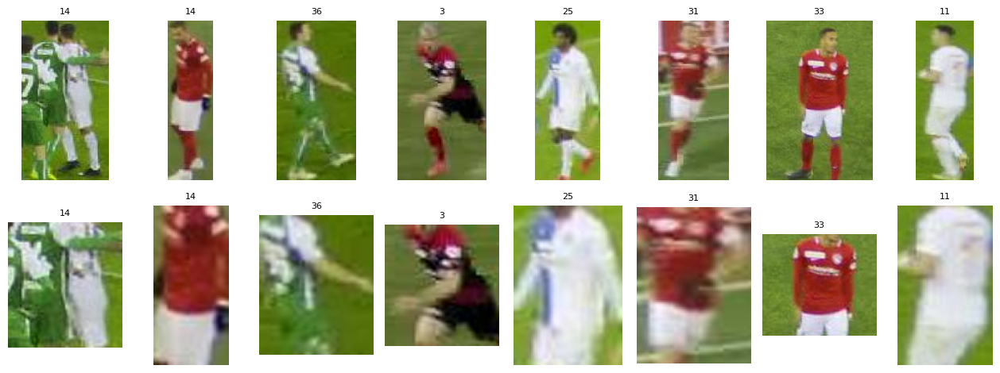

In [ ]:
TORSO_H = 128

def torso_crop(img, top=1/6, bottom=1/3, side=0.08):
    h, w = img.shape[:2]
    y0, y1 = int(round(h * top)), int(round(h * (1 - bottom)))
    x0, x1 = int(round(w * side)), int(round(w * (1 - side)))
    return img[y0:max(y1, y0 + 1), x0:max(x1, x0 + 1)]

def upscale(img, target_h=TORSO_H):
    s = target_h / img.shape[0]
    return cv2.resize(img, (max(1, int(round(img.shape[1] * s))), target_h), interpolation=cv2.INTER_CUBIC)

def get_torso(path):
    return upscale(torso_crop(cv2.imread(path)))

def show_grid(imgs, titles=None, cols=8, size=1.6):
    rows = math.ceil(len(imgs) / cols)
    plt.figure(figsize=(cols * size, rows * size * 1.5))
    for i, im in enumerate(imgs):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap='gray')
        if titles is not None:
            plt.title(str(titles[i]), fontsize=8)
        plt.axis('off')
    plt.tight_layout(); plt.show()

ex = random.Random(1).sample([it for it in items if it['gt'] >= 0], 8)
show_grid([cv2.imread(it['path']) for it in ex] + [get_torso(it['path']) for it in ex], [it['gt'] for it in ex] * 2)

### 1.2 Image quality: size and sharpness
**Sharpness = variance of the Laplacian.** The Laplacian is an edge filter: sharp images have strong edges
(high variance), blurry images weak ones (low variance).

usable (>= 40px): 7892/8544 | height percentiles 10/50/90: [ 50.  95. 139.]


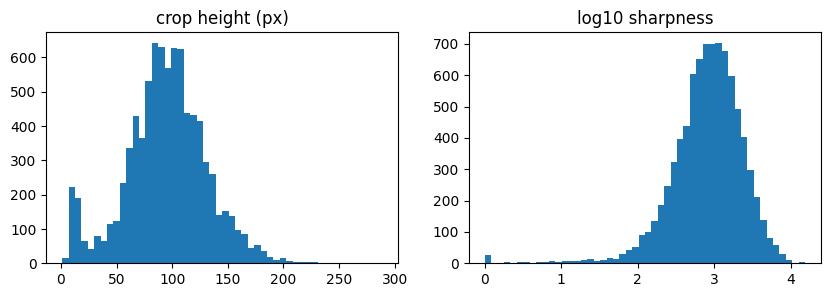

In [ ]:
MIN_H = 40     # players shorter than this are unreadable mush

def sharpness(img_bgr):
    return float(cv2.Laplacian(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var())

def add_quality(items_):
    """Adds height, sharpness and the size filter to every still."""
    for it in items_:
        img = cv2.imread(it['path'])
        it['h'] = img.shape[0]
        it['sharp'] = sharpness(torso_crop(img)) if img.shape[0] >= 8 else 0.0
        it['usable'] = it['h'] >= MIN_H

add_quality(items); add_quality(test_items)
H = np.array([it['h'] for it in items])
print(f"usable (>= {MIN_H}px): {sum(it['usable'] for it in items)}/{len(items)} "
      f"| height percentiles 10/50/90: {np.percentile(H, [10, 50, 90]).round()}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(H, 50); ax[0].set_title('crop height (px)')
ax[1].hist(np.log10(np.array([it['sharp'] for it in items]) + 1), 50); ax[1].set_title('log10 sharpness')
plt.show()

### 1.3 Hand-labelled "readable" set
Labels are per player, so many frames don't show the number. We hand-checked stills: **can a human read the
number?** The readable ones are our fair per-image test set. Set `RUN_LABELLING = True` to label more
(click the readable ones, then "Save & next grid").

In [ ]:
LEGIBLE_FILE = os.path.join(WORK, 'legible_labels.json')            # evaluation labels (readable set, test)
B3_FILE = os.path.join(WORK, 'legible_labels_b3.json')               # extra dev labels, ONLY to train B3
legible = json.load(open(LEGIBLE_FILE)) if os.path.exists(LEGIBLE_FILE) else {}
legible_b3 = json.load(open(B3_FILE)) if os.path.exists(B3_FILE) else {}

if RUN_LABELLING:
    import ipywidgets as W
    from IPython.display import display, clear_output
    pool_src = [it for it in items if it['split'] == 'dev'] if LABEL_SPLIT == 'dev' else test_items
    label_pool = [it for it in pool_src if it['gt'] >= 0 and it['usable']]
    random.Random(SEED).shuffle(label_pool)
    state, status, out = {}, W.Label(), W.Output()
    target, target_file = (legible_b3, B3_FILE) if LABEL_SPLIT == 'dev' else (legible, LEGIBLE_FILE)

    def render():
        todo = [it for it in label_pool if it['path'] not in legible and it['path'] not in legible_b3]
        status.value = f'{len(target)} labelled in this file, {sum(target.values())} readable'
        if not todo:
            return
        state['batch'] = todo[:24]
        state['toggles'], tiles = [], []
        for it in state['batch']:
            img = W.Image(value=cv2.imencode('.png', get_torso(it['path']))[1].tobytes(), format='png',
                          layout=W.Layout(width='100px', height='128px', object_fit='contain'))
            tb = W.ToggleButton(value=False, description=f"#{it['gt']}", layout=W.Layout(width='100px'))
            tb.observe(lambda ch, b=tb: setattr(b, 'button_style', 'success' if ch['new'] else ''), names='value')
            state['toggles'].append(tb)
            tiles.append(W.VBox([img, tb], layout=W.Layout(align_items='center')))
        with out:
            clear_output(wait=True)
            display(W.GridBox(tiles, layout=W.Layout(grid_template_columns='repeat(8, 110px)', grid_gap='6px')))

    def save_and_next(_):
        for it, tb in zip(state['batch'], state['toggles']):
            target[it['path']] = tb.value
        json.dump(target, open(target_file, 'w'))
        render()

    btn = W.Button(description='Save & next grid', button_style='primary', layout=W.Layout(width='180px'))
    btn.on_click(save_and_next)
    display(W.HBox([btn, status]), out)
    render()

Output()

In [ ]:
# The image sets used from here on
labelled = [it for it in items if it['path'] in legible]          # hand-checked train stills
readable = [it for it in labelled if legible[it['path']]]          # ... that a human can read
unread = [it for it in labelled if not legible[it['path']]]
test_labelled = [it for it in test_items if it['path'] in legible]
print(f'train: {len(labelled)} hand-labelled, {len(readable)} readable | test: {len(test_labelled)} hand-labelled')

if labelled:   # how readability depends on size
    hs = np.array([it['h'] for it in labelled]); ok = np.array([legible[it['path']] for it in labelled])
    edges = np.unique(np.percentile(hs, [0, 25, 50, 75, 100]))
    print('% readable by height:', ', '.join(f'{lo:.0f}-{hi:.0f}px: {ok[(hs >= lo) & (hs <= hi)].mean():.0%}'
                                             for lo, hi in zip(edges[:-1], edges[1:])))

train: 168 hand-labelled, 47 readable | test: 0 hand-labelled
% readable by height: 50-86px: 10%, 86-105px: 16%, 105-126px: 24%, 126-188px: 59%


## Pipeline switches
Every design choice that the **ablation study (A1)** turns off lives in `CFG`. Normal runs use the defaults.

In [ ]:
CFG_DEFAULT = dict(
    grass='colour',        # 'colour' = remove this image's grass colour | 'hsv' = generic green threshold
    search='silhouette',   # where to look for the number: 'silhouette' (player outline) | 'shirt' (shirt-colour hull)
    local_mask=True,       # also use the local-contrast masks (Step 3)
    strict=True,           # also use the stricter thresholds x1.3 and x1.6 (Step 3)
    clear_border=True,     # delete blobs touching left/right/bottom (Step 3)
    top_k=6,               # candidates passed from Step 4 to Step 5
    geo_mean=True,         # candidate confidence = geometric mean (else product) of digit probabilities
    one_penalty=0.7,       # multiplies the confidence of a lone '1' (1.0 = off)
    deblur=None,           # A4: None | 'unsharp' | 'wiener'
    chroma_mask=False,     # B1: also threshold colour-only contrast (LAB a,b) for pale numbers on white kits
    crops=((1/6, 1/3),),   # B2: torso windows (top, bottom) to try; the most confident reading wins
)
CFG = dict(CFG_DEFAULT)

class use_cfg:
    """with use_cfg(local_mask=False): ...  -> runs with changed switches, then restores them."""
    def __init__(self, **changes): self.changes = changes
    def __enter__(self): self.saved = dict(CFG); CFG.update(self.changes)
    def __exit__(self, *a): CFG.clear(); CFG.update(self.saved)

## Step 2: Find the shirt
The number is "pixels on the player whose colour differs strongly from the shirt". So we first find the shirt.

### 2.1 Grass removal
* **HSV** separates hue from brightness, so "green" is one threshold on hue and saturation.
* We then remove only pixels close (ΔE < 18) to **this image's grass colour**: a generic green threshold also
  deleted green shirts and lime numbers.

In [ ]:
from sklearn.cluster import KMeans

def grass_mask(bgr):
    """Generic grass: green hue with enough saturation (HSV threshold)."""
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, (33, 50, 30), (90, 255, 255)) > 0

def grass_colour_mask(lab, g, max_dE=18):
    """Pixels close to THIS image's grass colour (median LAB colour of the generic grass pixels)."""
    if g.sum() < 20:
        return np.zeros(g.shape, bool), None
    gcol = np.median(lab[g], axis=0)
    return np.linalg.norm(lab - gcol, axis=2) < max_dE, gcol

### 2.2 Shirt colour with K-means in LAB
In **LAB**, the distance between two colours roughly matches how different they look (Pan et al. 2024 found
it best for kit colours). **K-means (k = 3)** groups the torso pixels into 3 colours; the biggest is the shirt.

In [ ]:
def shirt_colour(lab, bad, k=3):
    """Biggest K-means cluster (in LAB) of the torso pixels that are not grass."""
    h = lab.shape[0]
    px = lab[h // 10: 9 * h // 10][~bad[h // 10: 9 * h // 10]]
    if len(px) < 30:
        return None
    km = KMeans(n_clusters=k, n_init=3, random_state=SEED).fit(px[::2])
    return km.cluster_centers_[np.bincount(km.labels_, minlength=k).argmax()]

### 2.3 Contrast map and search region
* **Contrast map ΔE** = LAB distance of each pixel to the shirt colour. Shirt is dark, the number lights up.
* **Region** = closing → largest connected component → convex hull. We search inside the **player silhouette**
  (everything that isn't grass): the tighter shirt-colour region missed numbers on striped kits.
* A **bilateral filter** first removes JPEG noise while keeping edges sharp.

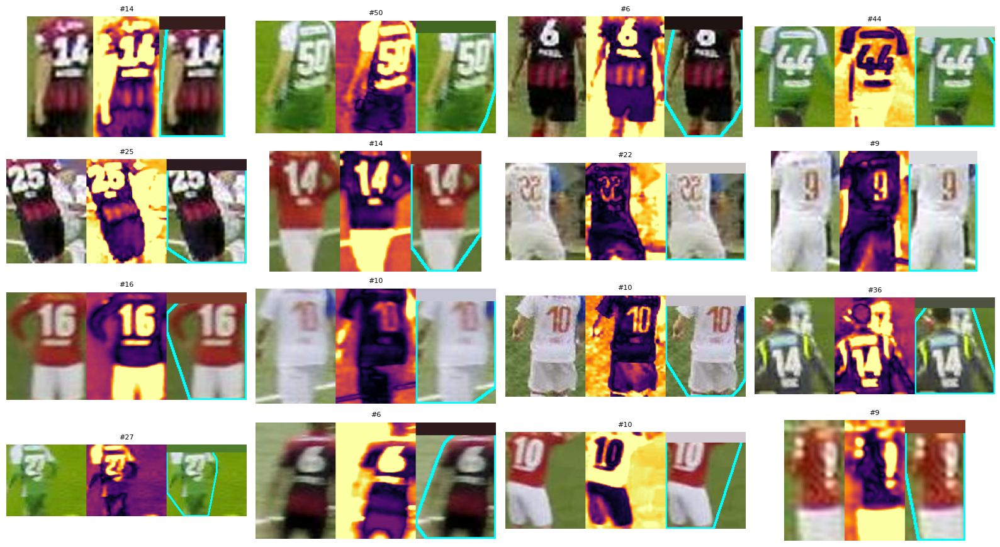

In [ ]:
def hull_of_largest(m, close_frac=6):
    """Morphological closing -> largest connected component -> its convex hull."""
    h, w = m.shape
    ksz = max(3, w // close_frac) | 1
    closed = cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_CLOSE,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksz, ksz)))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(closed, 8)
    if n < 2:
        return np.zeros((h, w), bool)
    big = 1 + st[1:, cv2.CC_STAT_AREA].argmax()
    cnts, _ = cv2.findContours((lbl == big).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    r = np.zeros((h, w), np.uint8)
    cv2.drawContours(r, [cv2.convexHull(np.vstack(cnts))], -1, 1, -1)
    return r > 0

def shirt_analysis(torso_bgr, shirt_dE=25):
    """Step 2: shirt colour, contrast map dE, search region."""
    smooth = cv2.bilateralFilter(torso_bgr, 5, 40, 5)                   # denoise, keep edges
    lab = cv2.cvtColor(smooth, cv2.COLOR_BGR2LAB).astype(np.float32)
    g = grass_mask(smooth)
    grass, _ = grass_colour_mask(lab, g) if CFG['grass'] == 'colour' else (g, None)
    shirt = shirt_colour(lab, grass)
    if shirt is None:
        return None
    dE = np.linalg.norm(lab - shirt, axis=2)                            # number lights up
    shirt_px = (dE < shirt_dE) & ~grass
    region = hull_of_largest(~grass) if CFG['search'] == 'silhouette' else hull_of_largest(shirt_px)
    if not region.any():
        return None
    return dict(lab=lab, shirt=shirt, dE=dE, shirt_px=shirt_px, region=region, grass=grass)

def step2_panel(t, sa):
    """torso | contrast map | search region (cyan) with the shirt colour as a strip on top."""
    dE_vis = cv2.applyColorMap(np.clip(sa['dE'] * 2.5, 0, 255).astype(np.uint8), cv2.COLORMAP_INFERNO)
    over = t.copy()
    cnts, _ = cv2.findContours(sa['region'].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(over, cnts, -1, (255, 255, 0), 2)
    over[:14] = cv2.cvtColor(np.uint8([[np.clip(sa['shirt'], 0, 255)]]), cv2.COLOR_LAB2BGR)[0, 0]
    return np.hstack([t, dE_vis, over])

def show_panels(panels, titles, cols=4, w=4, h=2.2):
    rows = math.ceil(len(panels) / cols)
    plt.figure(figsize=(cols * w, rows * h))
    for i, p in enumerate(panels):
        plt.subplot(rows, cols, i + 1); plt.imshow(p[..., ::-1]); plt.title(titles[i], fontsize=8); plt.axis('off')
    plt.tight_layout(); plt.show()

if SHOW_CHECKS and readable:
    ps = [(get_torso(it['path']), it) for it in readable[:16]]
    show_panels([step2_panel(t, shirt_analysis(t)) for t, _ in ps], [f"#{it['gt']}" for _, it in ps])

## Step 3: Number mask
* **Otsu** picks the threshold that best splits the pixels in two groups (number vs shirt), computed only
  inside the search region. A floor stops it from cutting into plain shirt noise.
* **Global** contrast = to the one shirt colour; **local** contrast = to the neighbourhood (a large **median
  filter** estimates the background), which helps on shaded white shirts.
* **Stricter thresholds** (x1.3, x1.6) separate a number that merged with an arm.
* **Opening** removes specks, **closing** reconnects broken strokes, **border clearing** deletes blobs touching
  the left/right/bottom edge (arms, other players, shorts).

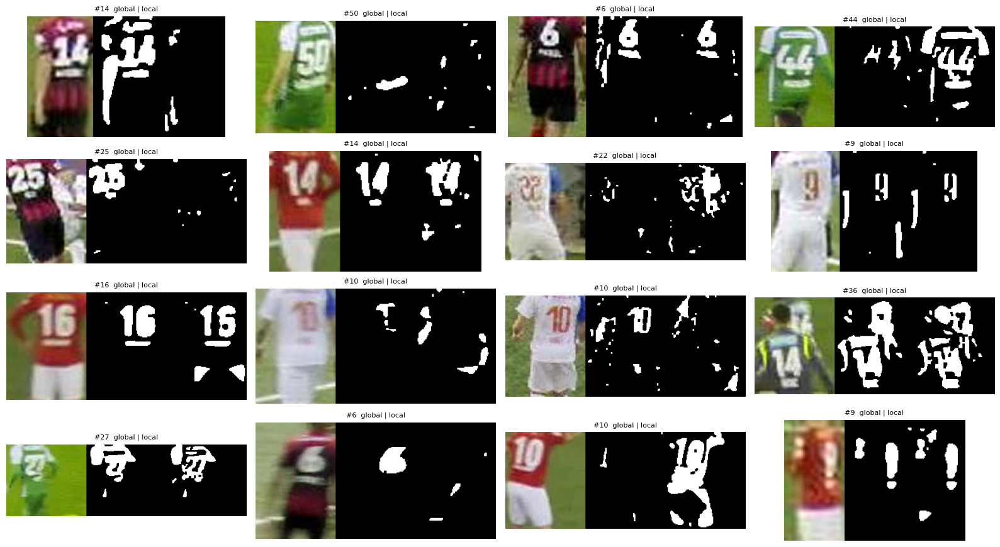

In [ ]:
def otsu_on(values, floor):
    """Otsu threshold computed only on the given pixels, never below `floor`."""
    v = np.clip(values, 0, 255).astype(np.uint8).reshape(-1, 1)
    t, _ = cv2.threshold(v, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return max(float(t), floor)

def clean(m, open_k=2, close_k=3):
    m = m.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((open_k, open_k), np.uint8))     # remove specks
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((close_k, close_k), np.uint8))  # reconnect strokes
    return m > 0

def clear_border_sides(m):
    """Delete blobs touching the left, right or bottom border (the top is allowed)."""
    n, lbl = cv2.connectedComponents(m.astype(np.uint8), connectivity=8)
    touch = set(np.unique(lbl[:, 0])) | set(np.unique(lbl[:, -1])) | set(np.unique(lbl[-1, :]))
    touch.discard(0)
    return m & ~np.isin(lbl, list(touch))

def local_contrast(lab, frac=0.5):
    """Distance of each pixel to its local background, estimated with a large median filter."""
    k = max(5, int(lab.shape[1] * frac)) | 1
    bg = np.dstack([cv2.medianBlur(np.clip(lab[..., i], 0, 255).astype(np.uint8), k) for i in range(3)])
    return np.linalg.norm(lab - bg.astype(np.float32), axis=2)

def number_masks(sa):
    """Step 3: candidate number masks (global/local contrast at 1-3 strictness levels)."""
    search = sa['region'] & ~sa['grass']
    if search.sum() < 30:
        return {}
    maps = [('global', sa['dE'], 30)]
    if CFG['local_mask']:
        maps.append(('local', local_contrast(sa['lab']), 15))
    if CFG['chroma_mask']:                                   # B1: colour difference only, brightness ignored
        maps.append(('chroma', np.linalg.norm(sa['lab'][..., 1:] - sa['shirt'][1:], axis=2), 12))
    factors = (1.0, 1.3, 1.6) if CFG['strict'] else (1.0,)
    out = {}
    for name, cmap, floor in maps:
        t0 = otsu_on(cmap[search], floor)
        for f in factors:
            m = clean((cmap > t0 * f) & search)
            out[name if f == 1.0 else f'{name}x{f}'] = clear_border_sides(m) if CFG['clear_border'] else m
    return out

if SHOW_CHECKS and readable:
    to3 = lambda m: cv2.cvtColor((m * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    panels = []
    for t, _ in ps:
        ms = number_masks(shirt_analysis(t))
        panels.append(np.hstack([t, to3(ms['global']), to3(ms.get('local', ms['global']))]))
    show_panels(panels, [f"#{it['gt']}  global | local" for _, it in ps])

## Step 4: Split the mask into digits
* **Connected components**: every separate blob. A digit must be 18–80% of the torso height, width/height
  0.1–1.4, fill ratio 0.2–0.9, and sit on the shirt (≥ 70% non-grass around it).
* **Pairs** = two blobs of similar height, side by side, close together.
* **Touching digits**: a too-wide blob is cut at the minimum of its **vertical projection profile**.
* The **top 6 candidates** go to Step 5, which picks the one it reads most confidently.

In [ ]:
def ring_fraction(ok_mask, x, y, w, h, pad=3):
    """Share of a thin ring around a box that is 'ok' (here: not grass)."""
    H, W = ok_mask.shape
    x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)
    ring = np.ones((y1 - y0, x1 - x0), bool)
    ring[y - y0:y - y0 + h, x - x0:x - x0 + w] = False
    return ok_mask[y0:y1, x0:x1][ring].mean() if ring.any() else 0.0

def digit_components(mask, sa):
    """Connected components shaped like a single digit."""
    H, W = mask.shape
    n, lbl, st, cents = cv2.connectedComponentsWithStats(mask.astype(np.uint8), 8)
    comps = []
    for i in range(1, n):
        x, y, w, h, area = st[i]
        if not (0.18 * H <= h <= 0.8 * H): continue                    # digit height
        if w < 2 or not (0.1 <= w / h <= 1.4): continue                # thin '1' ... two touching digits
        if not (0.2 <= area / (w * h) <= 0.9): continue                # not a speck, not a solid block
        if ring_fraction(~sa['grass'], x, y, w, h) < 0.7: continue     # sits on the shirt
        cm = lbl[y:y + h, x:x + w] == i
        comps.append(dict(x=int(x), y=int(y), w=int(w), h=int(h), cx=float(cents[i][0]), mask=cm,
                          contrast=float(sa['dE'][y:y + h, x:x + w][cm].mean())))
    return comps

def split_wide(c):
    """Cut a wide blob at the minimum of its column sums (vertical projection profile)."""
    m = c['mask']; cols = m.sum(0).astype(float)
    a, b = int(.3 * len(cols)), int(.7 * len(cols))
    if b - a < 2:
        return [c]
    cut = a + int(np.argmin(cols[a:b])); parts = []
    for off, sub in ((0, m[:, :cut]), (cut, m[:, cut:])):
        ys, xs = np.where(sub.any(1))[0], np.where(sub.any(0))[0]
        if len(ys) == 0 or len(xs) == 0:
            return [c]
        parts.append(dict(c, x=c['x'] + off + int(xs[0]), y=c['y'] + int(ys[0]), w=len(xs), h=int(ys[-1] - ys[0] + 1),
                          cx=c['x'] + off + float(xs.mean()), mask=sub[ys[0]:ys[-1] + 1, xs[0]:xs[-1] + 1]))
    return parts

def group_score(g, W, H, split=False):
    """Higher = more number-like (tall, high contrast, centred, upper torso). None = not a valid pair."""
    hs = [c['h'] for c in g]
    cy = np.mean([c['y'] + c['h'] / 2 for c in g]) / H
    s = np.mean(hs) / H + np.mean([c['contrast'] for c in g]) / 150 - abs(np.mean([c['cx'] for c in g]) / W - .5)
    s -= 2 * max(0, cy - 0.6)                                          # numbers sit in the upper torso
    if len(g) == 2:
        a, b = sorted(g, key=lambda c: c['x'])
        if max(hs) / min(hs) > 1.35: return None                      # similar heights
        if min(a['y'] + a['h'], b['y'] + b['h']) - max(a['y'], b['y']) < .6 * min(hs): return None   # side by side
        gap = b['x'] - (a['x'] + a['w'])
        if gap > .6 * max(hs) or gap < -.2 * max(hs): return None       # close together
        if not split: s += .1                                           # bonus: two separate digits
    return s

def segment_digits(sa, masks):
    """Step 4: candidate groups of 1-2 digits from all masks, best first."""
    H, W = sa['dE'].shape
    cands = []
    for name, m in masks.items():
        base = digit_components(m, sa)
        groups = []                                     # (blobs, made_by_splitting)
        for i, a in enumerate(base):
            r = a['w'] / a['h']
            parts = split_wide(a) if r > .7 else [a]
            if r > .85 and len(parts) == 2:
                groups.append((parts, False))           # very wide: two touching digits
            else:
                groups.append(([a], False))
                if len(parts) == 2: groups.append((parts, True))
            for b in base[i + 1:]:
                groups.append(([a, b], False))
        for g, was_split in groups:
            s = group_score(g, W, H, split=was_split)
            if s is not None:
                cands.append(dict(score=float(s), source=name, boxes=sorted(g, key=lambda c: c['x'])))
    cands.sort(key=lambda c: -c['score'])
    return cands[:CFG['top_k']]

def draw_boxes(t, boxes, col=(0, 0, 255)):
    v = t.copy()
    for b in boxes:
        cv2.rectangle(v, (b['x'], b['y']), (b['x'] + b['w'] - 1, b['y'] + b['h'] - 1), col, 1)
    return v

### 4.1 Check Steps 2–4 on the readable images
Scored automatically: does the best candidate (or any of the top 6) have the right **number of digits**?

right digit count: best candidate 17/47 | among top 6: 35/47


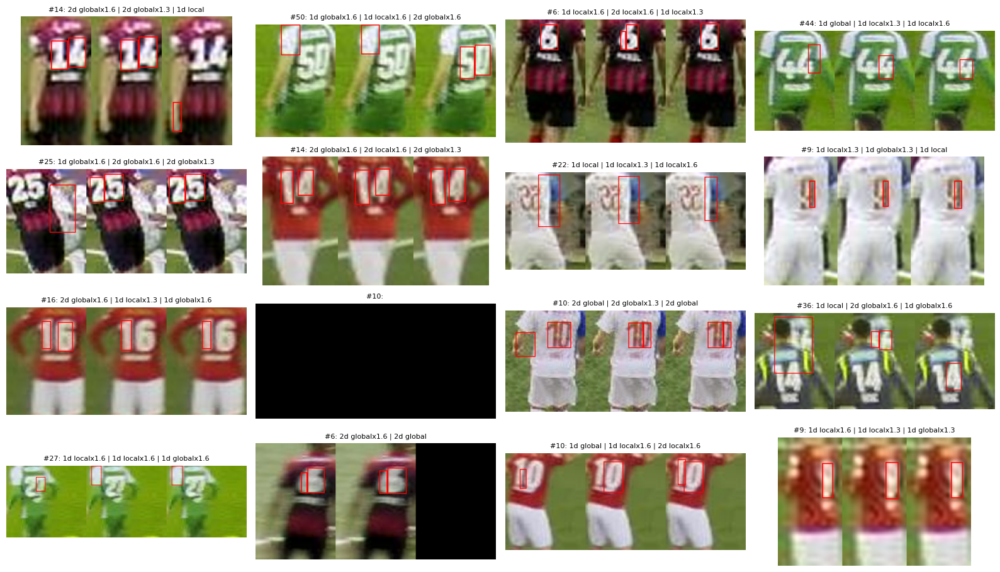

In [ ]:
def candidates_for(t):
    sa = shirt_analysis(t)
    return sa, (segment_digits(sa, number_masks(sa)) if sa else [])

if readable:
    top1 = topk = 0
    panels, titles = [], []
    for it in readable:
        t = get_torso(it['path']); _, cands = candidates_for(t)
        n = len(str(it['gt']))
        top1 += bool(cands) and len(cands[0]['boxes']) == n
        topk += any(len(c['boxes']) == n for c in cands)
        panels.append(np.hstack([draw_boxes(t, c['boxes']) for c in cands[:3]] + [t * 0] * (3 - len(cands[:3]))))
        titles.append(f"#{it['gt']}: " + ' | '.join(f"{len(c['boxes'])}d {c['source']}" for c in cands[:3]))
    print(f'right digit count: best candidate {top1}/{len(readable)} | among top {CFG["top_k"]}: {topk}/{len(readable)}')
    if SHOW_CHECKS:
        show_panels(panels[:16], titles[:16], h=2.3)

## Step 5: Read the digits

### 5.1 Training digits, part 1: realistic synthetic players
We draw a simple player (random kit, stripes, font, number) at 4x size, then shrink, blur, add noise and JPEG
compression so it looks like SoccerNet. Each one goes through **our own Steps 2–4**, and digits are kept only if
their boxes lie on the drawn number (so the labels are trustworthy).

In [ ]:
import matplotlib
from PIL import Image, ImageDraw, ImageFont

FONTS = [f for f in glob.glob('/usr/share/fonts/truetype/**/*Bold*.ttf', recursive=True)
         + [os.path.join(matplotlib.get_data_path(), 'fonts/ttf', n)
            for n in ('DejaVuSans-Bold.ttf', 'DejaVuSansMono-Bold.ttf', 'DejaVuSerif-Bold.ttf')]
         if os.path.exists(f)][:15]
PALETTE = [(255,255,255),(20,20,20),(200,30,30),(30,40,150),(250,220,0),(30,120,60),(240,120,20),
           (120,20,40),(90,180,230),(150,150,150),(200,255,60)]

def colour_dist(a, b):
    la, lb = (cv2.cvtColor(np.uint8([[c]]), cv2.COLOR_RGB2LAB)[0, 0].astype(float) for c in (a, b))
    return np.linalg.norm(la - lb)

def jitter(c, rng, a=25):
    return tuple(int(np.clip(v + rng.randint(-a, a), 0, 255)) for v in c)

def synth_player(number, rng, S=4):
    """Fake back-view player at real SoccerNet size. Returns (image, mask of the drawn number)."""
    W, H = rng.randint(30, 50), rng.randint(80, 130)
    Wb, Hb = W * S, H * S
    im = Image.new('RGB', (Wb, Hb), (rng.randint(40, 90), rng.randint(120, 170), rng.randint(30, 70)))   # grass
    d = ImageDraw.Draw(im)
    shirt = jitter(rng.choice(PALETTE), rng)
    numc = rng.choice([c for c in PALETTE if colour_dist(c, shirt) > 45])
    skin = jitter((200, 150, 120), rng, 40)
    cx = Wb // 2 + rng.randint(-Wb // 10, Wb // 10)
    tw = int(Wb * rng.uniform(.55, .8)); ty0, ty1 = int(Hb * .17), int(Hb * .6)
    d.ellipse((cx - Wb * .13, Hb * .02, cx + Wb * .13, Hb * .18), fill=(40, 30, 20))                # head
    for side in (-1, 1):                                                                          # arms
        xa = cx + side * tw // 2
        d.rectangle((min(xa, xa + side * Wb * .1), ty0 + 5, max(xa, xa + side * Wb * .1), ty1 - Hb * .1),
                    fill=skin if rng.random() < .6 else shirt)
    d.rounded_rectangle((cx - tw // 2, ty0, cx + tw // 2, ty1), radius=S * 3, fill=shirt)          # shirt
    if rng.random() < .25:                                                                        # stripes
        sc, horiz = jitter(rng.choice(PALETTE), rng), rng.random() < .5
        for p in range(0, Hb if horiz else Wb, S * 8):
            if horiz and ty0 + p < ty1: d.rectangle((cx - tw // 2, ty0 + p, cx + tw // 2, ty0 + p + S * 3), fill=sc)
            if not horiz and cx - tw // 2 + p < cx + tw // 2: d.rectangle((cx - tw // 2 + p, ty0, cx - tw // 2 + p + S * 3, ty1), fill=sc)
    d.rectangle((cx - tw // 2, ty1, cx + tw // 2, Hb * .8), fill=jitter(rng.choice(PALETTE), rng))  # shorts
    d.rectangle((cx - tw // 2.5, Hb * .8, cx + tw // 2.5, Hb), fill=skin)                           # legs
    layer = Image.new('L', (Wb, Hb), 0)                                                           # the number
    ny = ty0 + (ty1 - ty0) * rng.uniform(.38, .55)
    font = ImageFont.truetype(rng.choice(FONTS), int((ty1 - ty0) * rng.uniform(.45, .7)))
    ImageDraw.Draw(layer).text((cx + rng.randint(-S * 2, S * 2), ny), str(number), fill=255, font=font, anchor='mm')
    layer = layer.rotate(rng.uniform(-10, 10), center=(cx, ny))
    if rng.random() < .3:                                                                         # outline
        im.paste(jitter(rng.choice(PALETTE), rng), mask=Image.fromarray(cv2.dilate(np.array(layer), np.ones((S + 1, S + 1), np.uint8))))
    im.paste(numc, mask=layer)
    a = cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)
    if rng.random() < .6:                                                                         # motion blur
        k = rng.randint(3, 4 * S); ker = np.zeros((k, k)); ker[k // 2, :] = 1 / k
        a = cv2.filter2D(a, -1, ker)
    a = cv2.resize(a, (W, H), interpolation=cv2.INTER_AREA)                                       # real size
    a = cv2.GaussianBlur(a, (3, 3), rng.uniform(.1, 1.0))
    a = np.clip(a + np.random.normal(0, rng.uniform(2, 8), a.shape), 0, 255).astype(np.uint8)    # noise
    _, enc = cv2.imencode('.jpg', a, [cv2.IMWRITE_JPEG_QUALITY, rng.randint(35, 85)])               # JPEG
    return cv2.imdecode(enc, 1), cv2.resize(np.array(layer), (W, H), interpolation=cv2.INTER_AREA) > 60

def sample_number(rng):
    return rng.randint(1, 9) if rng.random() < .3 else rng.randint(10, 99)

### 5.2 Digit patches
Each digit box is cut from the contrast map, stretched to 0–255, resized to fit 22 px (shape kept) and centred
in 28x28. Every digit then has the same size and brightness, always bright on dark.

synthetic digits: 6318 [251 671 621 690 625 676 754 603 737 690]


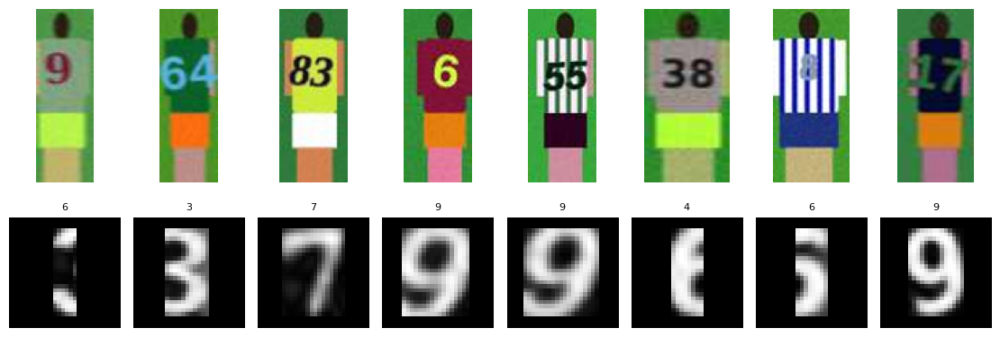

In [ ]:
def normalize_patch(p, size=28, inner=22):
    p = p.astype(np.float32)
    p = (p - p.min()) / (p.max() - p.min() + 1e-6) * 255                      # contrast stretch
    h, w = p.shape; s = inner / max(h, w)
    r = cv2.resize(p, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    out = np.zeros((size, size), np.float32)
    y0, x0 = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    out[y0:y0 + r.shape[0], x0:x0 + r.shape[1]] = r
    return out.astype(np.uint8)

def candidate_patches(sa, cand):
    return [normalize_patch(sa['dE'][b['y']:b['y'] + b['h'], b['x']:b['x'] + b['w']]) for b in cand['boxes']]

def process_torso(t):
    """Steps 2-4 on one torso (with optional deblurring from A4)."""
    if CFG['deblur']:
        t = deblur(t, CFG['deblur'])
    return candidates_for(t)

def build_synthetic_digits(n_players, seed=0):
    rng = random.Random(seed); np.random.seed(seed)
    X, y, used, t0 = [], [], 0, time.time()
    for i in range(n_players):
        n = sample_number(rng); s = str(n)
        img, nm = synth_player(n, rng)
        nm_t = upscale(torso_crop(nm.astype(np.uint8) * 255)) > 127               # where the number really is
        sa, cands = process_torso(upscale(torso_crop(img)))
        for c in cands:
            if len(c['boxes']) == len(s) and all(
                    nm_t[b['y']:b['y'] + b['h'], b['x']:b['x'] + b['w']][b['mask']].mean() > .5 for b in c['boxes']):
                X += candidate_patches(sa, c); y += [int(ch) for ch in s]; used += 1
                break
        if (i + 1) % 1000 == 0:
            print(f'{i+1}/{n_players} players, {used} usable, {len(y)} digits, {time.time()-t0:.0f}s')
    return np.array(X), np.array(y)

SYN_FILE = os.path.join(WORK, 'synthetic_digits.npz')
if not os.path.exists(SYN_FILE):
    X_syn, y_syn = build_synthetic_digits(N_SYNTH)
    np.savez(SYN_FILE, X=X_syn, y=y_syn)
d = np.load(SYN_FILE); X_syn, y_syn = d['X'], d['y']
print('synthetic digits:', len(y_syn), np.bincount(y_syn, minlength=10))
rng = random.Random(3)
show_grid([upscale(synth_player(sample_number(rng), rng)[0]) for _ in range(8)] + list(X_syn[:8]),
          [''] * 8 + list(y_syn[:8]), cols=8, size=1.4)

### 5.3 Three digit classifiers (all trained from scratch)
All share one interface, `predict_proba(list of 28x28 patches) -> (n, 10) probabilities`, so any of them can
be plugged into the reader. From simplest to most complex:

1. **Shape features + kNN / SVM** (the professor's baseline): from the binarized digit (Otsu), we measure
   * **holes** with contour hierarchy (0 → 1 hole, 8 → 2, 1 → none) and **where the hole is** (6 vs 9),
   * **aspect ratio** and **fill ratio**,
   * **Hu moments**: 7 numbers describing the shape, unchanged by size and position,
   * **3x3 zoning**: share of white pixels in each cell of a 3x3 grid.
2. **HOG + SVM**: Histogram of Oriented Gradients = which way the edges point in each 7x7 cell.
3. **Small CNN** designed and trained here from scratch (no pretrained weights).

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from skimage.feature import hog

def shape_features(patch):
    """22 contour/shape features of the digit in a 28x28 patch."""
    _, b = cv2.threshold(patch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = (b > 0).astype(np.uint8)
    n, lbl, st, _ = cv2.connectedComponentsWithStats(m, 8)
    if n < 2:
        return np.zeros(22)
    m = (lbl == 1 + st[1:, cv2.CC_STAT_AREA].argmax()).astype(np.uint8)        # keep the main blob
    ys, xs = np.nonzero(m)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    crop = m[y0:y1, x0:x1]
    h, w = crop.shape
    cnts, hier = cv2.findContours(m, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_NONE)
    holes = [c for c, hh in zip(cnts, hier[0]) if hh[3] >= 0 and cv2.contourArea(c) >= 2]   # inner contours
    n_holes = min(len(holes), 2)
    hole_y = np.mean([cv2.boundingRect(c)[1] + cv2.boundingRect(c)[3] / 2 - y0 for c in holes]) / h if holes else -1
    hu = cv2.HuMoments(cv2.moments(crop, binaryImage=True)).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-12)                          # log scale: values span decades
    zones = cv2.resize(crop.astype(np.float32), (3, 3), interpolation=cv2.INTER_AREA).ravel()
    return np.concatenate([np.eye(3)[n_holes], [hole_y, w / h, crop.mean()], hu, zones])

def hog_features(patch):
    return hog(patch, orientations=9, pixels_per_cell=(7, 7), cells_per_block=(2, 2))

class FeatureRecognizer:
    """Features (shape or HOG) -> scaler -> classifier (kNN or SVM)."""
    def __init__(self, features, clf):
        self.features = features
        self.model = make_pipeline(StandardScaler(), clf)
    def fit(self, X, y):
        self.model.fit(np.array([self.features(x) for x in X]), y); return self
    def predict_proba(self, patches):
        return self.model.predict_proba(np.array([self.features(p) for p in patches]))

### 5.4 Training digits, part 2: real digits harvested from dev players
We know every dev player's number. For each dev frame we pick the candidate that best matches it and keep its
digits if the match is confident. Two rounds (round 2 uses a classifier that already saw round-1 digits).
Hand-labelled players are excluded so the test images stay clean.

In [ ]:
def read_candidates(sa, cands, rec):
    """Digit probabilities for every candidate."""
    return [rec.predict_proba(candidate_patches(sa, c)) for c in cands]

def harvest_real_digits(pool, rec, min_conf=0.3):
    X, y, used, t0 = [], [], 0, time.time()
    for i, it in enumerate(pool):
        s = str(it['gt'])
        sa, cands = process_torso(get_torso(it['path']))
        best, best_p = None, 0.0
        for c in cands:
            if len(c['boxes']) != len(s): continue
            patches = candidate_patches(sa, c)
            P = rec.predict_proba(patches)
            p = float(np.prod([P[k, int(ch)] for k, ch in enumerate(s)]) ** (1 / len(s)))   # match to the true number
            if p > best_p: best, best_p = patches, p
        if best is not None and best_p >= min_conf:
            X += best; y += [int(ch) for ch in s]; used += 1
        if (i + 1) % 1000 == 0:
            print(f'{i+1}/{len(pool)} frames, {used} used, {len(y)} digits, {time.time()-t0:.0f}s')
    return np.array(X).reshape(-1, 28, 28), np.array(y, int)

REAL_FILE = os.path.join(WORK, 'real_digits.npz')
if not os.path.exists(REAL_FILE):
    held = {it['tid'] for it in labelled}
    pool = [it for it in items if it['split'] == 'dev' and it['gt'] >= 0 and it['usable'] and it['tid'] not in held]
    r0 = FeatureRecognizer(hog_features, SVC(C=5, gamma='scale', probability=True, random_state=SEED)).fit(X_syn, y_syn)
    X1, y1 = harvest_real_digits(pool, r0)
    r1 = FeatureRecognizer(hog_features, SVC(C=5, gamma='scale', probability=True, random_state=SEED)).fit(
        np.concatenate([X_syn, X1]), np.concatenate([y_syn, y1]))
    X_real, y_real = harvest_real_digits(pool, r1)
    np.savez(REAL_FILE, X=X_real, y=y_real)
d = np.load(REAL_FILE); X_real, y_real = d['X'], d['y']
print('real digits:', len(y_real), np.bincount(y_real, minlength=10))

real digits: 769 [ 52 122  69 119  65  71  78  42  54  97]


### 5.5 Train and compare the classifiers on held-out digits
The same 85/15 split for every classifier. Held-out accuracy is shown separately for synthetic and real digits.

In [ ]:
def split_idx(n, frac=0.15, seed=SEED):
    p = np.random.RandomState(seed).permutation(n)
    return p[int(frac * n):], p[:int(frac * n)]

tr_s, te_s = split_idx(len(y_syn)); tr_r, te_r = split_idx(len(y_real))
X_tr = np.concatenate([X_syn[tr_s], X_real[tr_r]]); y_tr = np.concatenate([y_syn[tr_s], y_real[tr_r]])
X_te_syn, y_te_syn, X_te_real, y_te_real = X_syn[te_s], y_syn[te_s], X_real[te_r], y_real[te_r]

recognizers = {
    'shape+kNN': cached('rec_shape_knn', lambda: FeatureRecognizer(shape_features,
                        KNeighborsClassifier(n_neighbors=7, weights='distance')).fit(X_tr, y_tr)),
    'shape+SVM': cached('rec_shape_svm', lambda: FeatureRecognizer(shape_features,
                        SVC(C=5, gamma='scale', probability=True, random_state=SEED)).fit(X_tr, y_tr)),
    'HOG+SVM':   cached('rec_hog_svm', lambda: FeatureRecognizer(hog_features,
                        SVC(C=5, gamma='scale', probability=True, random_state=SEED)).fit(X_tr, y_tr)),
}

Optional: small CNN trained from scratch (runs on CPU in a few minutes; skipped if PyTorch is missing).

In [ ]:
try:
    import torch, torch.nn as nn, torch.nn.functional as F
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

    class SmallCNN(nn.Module):
        """3 conv layers + 2 fully connected; designed and trained from scratch."""
        def __init__(self):
            super().__init__()
            self.c1, self.c2, self.c3 = nn.Conv2d(1, 32, 3, padding=1), nn.Conv2d(32, 64, 3, padding=1), nn.Conv2d(64, 64, 3, padding=1)
            self.fc1, self.fc2, self.drop = nn.Linear(64 * 7 * 7, 128), nn.Linear(128, 10), nn.Dropout(0.3)
        def forward(self, x):
            x = F.max_pool2d(F.relu(self.c1(x)), 2)          # 28 -> 14
            x = F.max_pool2d(F.relu(self.c2(x)), 2)          # 14 -> 7
            x = F.relu(self.c3(x))
            return self.fc2(self.drop(F.relu(self.fc1(x.flatten(1)))))

    class CNNRecognizer:
        def fit(self, X, y, epochs=15, bs=128):
            torch.manual_seed(SEED)
            Xt = torch.tensor(X, dtype=torch.float32).unsqueeze(1) / 255.
            yt = torch.tensor(y, dtype=torch.long)
            self.model = SmallCNN().to(DEVICE)
            opt = torch.optim.Adam(self.model.parameters(), 1e-3)
            for _ in range(epochs):
                self.model.train()
                for b in torch.randperm(len(yt)).split(bs):
                    dx, dy = np.random.randint(-2, 3, 2)                       # random shift augmentation
                    xb = torch.roll(Xt[b], shifts=(int(dy), int(dx)), dims=(2, 3)).to(DEVICE)
                    loss = F.cross_entropy(self.model(xb), yt[b].to(DEVICE))
                    opt.zero_grad(); loss.backward(); opt.step()
            self.model.cpu(); return self
        def predict_proba(self, patches):
            self.model.eval()
            with torch.no_grad():
                x = torch.tensor(np.array(patches), dtype=torch.float32).unsqueeze(1) / 255.
                return F.softmax(self.model(x), 1).numpy()

    recognizers['CNN'] = cached('rec_cnn', lambda: CNNRecognizer().fit(X_tr, y_tr))
except ImportError:
    print('PyTorch not installed: CNN skipped')

def digit_acc(rec, X, y):
    return (rec.predict_proba(list(X)).argmax(1) == y).mean()

print(f"{'classifier':12s} {'synthetic':>10s} {'real':>8s}   (held-out digit accuracy)")
for name, rec in recognizers.items():
    print(f"{name:12s} {digit_acc(rec, X_te_syn, y_te_syn):10.1%} {digit_acc(rec, X_te_real, y_te_real):8.1%}")

classifier    synthetic     real   (held-out digit accuracy)
shape+kNN         66.1%    61.7%
shape+SVM         71.5%    68.7%
HOG+SVM           75.9%    96.5%
CNN               76.0%    74.8%


### 5.6 The reader: pick the candidate the classifier is most sure about
* Candidate confidence = **geometric mean** of its digit probabilities (fair to 1- and 2-digit numbers).
* A leading 0 or a lone 0 is not a valid number.
* A lone **"1"** is penalised (x0.7): arm edges and stripes look like 1s.

In [ ]:
def read_number(t, rec):
    """Returns (number or None, confidence, chosen candidate, predictions of all candidates)."""
    sa, cands = process_torso(t)
    best, preds = (None, 0.0, None), []
    for c, P in zip(cands, read_candidates(sa, cands, rec) if cands else []):
        digits = P.argmax(1)
        preds.append(int(''.join(map(str, digits))))
        if digits[0] == 0:
            continue
        conf = float(np.prod(P.max(1)))
        if CFG['geo_mean']:
            conf = conf ** (1 / len(digits))
        if len(digits) == 1 and digits[0] == 1:
            conf *= CFG['one_penalty']
        if conf > best[1]:
            best = (preds[-1], conf, c)
    return best[0], best[1], best[2], preds

def read_image(img, rec):
    """Read a full player crop: try every torso window in CFG['crops'], keep the most confident reading.
    Returns (number or None, confidence, chosen candidate, all predictions, torso used)."""
    best = None
    for top, bottom in CFG['crops']:
        t = upscale(torso_crop(img, top=top, bottom=bottom))
        num, conf, cand, preds = read_number(t, rec)
        if best is None or conf > best[1]:
            best = (num, conf, cand, preds + (best[3] if best else []), t)
        else:
            best = best[:3] + (best[3] + preds, best[4])
    return best

def readable_score(rec, items_=None):
    """Exact numbers read on the readable images + how often the right number was among the candidates."""
    items_ = readable if items_ is None else items_
    exact = ceiling = 0
    for it in items_:
        num, _, _, preds, _ = read_image(cv2.imread(it['path']), rec)
        exact += num == it['gt']; ceiling += it['gt'] in preds
    return exact, ceiling, len(items_)

print(f"{'classifier':12s} {'exact':>12s} {'ceiling':>12s}   (on the {len(readable)} readable images)")
for name, rec in recognizers.items():
    e, c, n = readable_score(rec)
    print(f"{name:12s} {e:5d} ({e/max(1,n):4.0%}) {c:5d} ({c/max(1,n):4.0%})")

classifier          exact      ceiling   (on the 47 readable images)
shape+kNN        6 ( 13%)    12 ( 26%)
shape+SVM        8 ( 17%)    16 ( 34%)
HOG+SVM         16 ( 34%)    20 ( 43%)
CNN             13 ( 28%)    17 ( 36%)


## Step 6: Decide and evaluate
Below a confidence threshold **τ** the system answers **"unreadable"** instead of guessing (our backup plan).

* **Frame level** (hand-labelled images): coverage (answered), precision (correct when answering), abstain rate
  on unreadable images.
* **Player level** (all val/test players, no hand labels needed): each player's 6 frames vote, weighted by
  confidence; no confident frame = "unreadable" (-1). This is how SoccerNet scores the task.
* τ is chosen on **val** players; **test** is scored once at that τ.

In [ ]:
def read_all(items_, rec, label=''):
    """Reader on every frame: prediction + confidence (τ is applied later)."""
    rows, t0 = [], time.time()
    for i, it in enumerate(items_):
        img = cv2.imread(it['path'])
        num, conf = None, 0.0
        if img is not None and img.shape[0] >= MIN_H:              # height only (crops are narrow)
            num, conf, _, _, _ = read_image(img, rec)
        rows.append(dict(path=it['path'], tid=it['tid'], gt=it['gt'], pred=num, conf=conf,
                         h=it['h'], sharp=it['sharp'], legible=legible.get(it['path'])))
        if (i + 1) % 2000 == 0:
            print(f'  {label} {i+1}/{len(items_)} frames, {time.time()-t0:.0f}s')
    return rows

def frame_metrics(rows, tau):
    rd = [r for r in rows if r['legible'] is True]
    un = [r for r in rows if r['legible'] is False]
    ans = [r for r in rd if r['pred'] is not None and r['conf'] >= tau]
    ok = sum(r['pred'] == r['gt'] for r in ans)
    return dict(tau=tau, coverage=len(ans) / max(1, len(rd)), precision=ok / max(1, len(ans)),
                accuracy=ok / max(1, len(rd)),
                abstain_unreadable=sum(r['pred'] is None or r['conf'] < tau for r in un) / max(1, len(un)))

def player_vote(rows, tau):
    """One answer per player: confidence-weighted vote of its frames; nothing confident -> -1."""
    by = defaultdict(list)
    for r in rows:
        by[r['tid']].append(r)
    out = {}
    for tid, rs in by.items():
        votes = Counter()
        for r in rs:
            if r['pred'] is not None and r['conf'] >= tau:
                votes[r['pred']] += r['conf']
        out[tid] = (votes.most_common(1)[0][0] if votes else -1, rs[0]['gt'])
    return out

def player_metrics(rows, tau):
    v = player_vote(rows, tau)
    vis = [(p, g) for p, g in v.values() if g >= 0]
    inv = [(p, g) for p, g in v.values() if g < 0]
    answered = [(p, g) for p, g in vis if p != -1]
    return dict(tau=tau, players=len(v),
                overall=sum(p == g for p, g in v.values()) / max(1, len(v)),        # -1 counts as a class
                visible_acc=sum(p == g for p, g in vis) / max(1, len(vis)),
                visible_coverage=len(answered) / max(1, len(vis)),
                visible_precision=sum(p == g for p, g in answered) / max(1, len(answered)),
                abstain_on_no_number=sum(p == -1 for p, g in inv) / max(1, len(inv)))

def fmt(d):
    return ' | '.join(f'{k}={v:.2f}' if isinstance(v, float) else f'{k}={v}' for k, v in d.items())

TAUS = np.round(np.arange(0, 0.96, 0.05), 2)
val_items = [it for it in items if it['split'] == 'val']

### 6.1 All classifiers on val (choose τ) and test (final score)
Predictions are saved to Drive, so this is slow (~4 min per classifier on test) only the first time.

In [ ]:
results, rows_by = {}, {}
for name, rec in recognizers.items():
    key = name.replace('+', '_')
    rows_by[name] = dict(lab=cached(f'rows_{key}_lab{len(labelled)}', lambda: read_all(labelled, rec, 'labelled')),
                         val=cached(f'rows_{key}_val', lambda: read_all(val_items, rec, 'val')),
                         test=cached(f'rows_{key}_test', lambda: read_all(test_items, rec, 'test')))
    tau = max(TAUS, key=lambda t: player_metrics(rows_by[name]['val'], t)['overall'])
    results[name] = dict(tau=float(tau), readable=frame_metrics(rows_by[name]['lab'], tau),
                         val=player_metrics(rows_by[name]['val'], tau), test=player_metrics(rows_by[name]['test'], tau))
    print(f'{name}: τ={tau}  TEST {fmt(results[name]["test"])}')

no_number = np.mean([test_labels[t] < 0 for t in {it['tid'] for it in test_items}])
MAIN = max(results, key=lambda n: results[n]['val']['overall'])     # best classifier on VAL
TAU = results[MAIN]['tau']
print(f'\nmain classifier (best on val): {MAIN}, τ = {TAU}')

cols = [('overall', 'Overall'), ('visible_acc', 'Visible: read'), ('visible_coverage', 'Visible: answered'),
        ('visible_precision', 'Correct when answering'), ('abstain_on_no_number', 'No number: "unreadable"')]
print(f"\n{'TEST players':26s}" + ''.join(f'{n:>12s}' for n in results))
for k, label in cols:
    print(f'{label:26s}' + ''.join(f"{results[n]['test'][k]:12.2f}" for n in results))
baseline_label = '(always "unreadable")'
print(f'{baseline_label:26s}{no_number:12.2f}')
json.dump(dict(results=results, main=MAIN, always_unreadable=float(no_number)),
          open(os.path.join(WORK, 'step6_results.json'), 'w'), indent=2)

shape+kNN: τ=0.85  TEST tau=0.85 | players=1211 | overall=0.29 | visible_acc=0.10 | visible_coverage=0.49 | visible_precision=0.20 | abstain_on_no_number=0.75
shape+SVM: τ=0.8  TEST tau=0.80 | players=1211 | overall=0.32 | visible_acc=0.07 | visible_coverage=0.15 | visible_precision=0.43 | abstain_on_no_number=0.93
HOG+SVM: τ=0.75  TEST tau=0.75 | players=1211 | overall=0.36 | visible_acc=0.15 | visible_coverage=0.39 | visible_precision=0.40 | abstain_on_no_number=0.84
CNN: τ=0.8  TEST tau=0.80 | players=1211 | overall=0.40 | visible_acc=0.19 | visible_coverage=0.39 | visible_precision=0.47 | abstain_on_no_number=0.93

main classifier (best on val): CNN, τ = 0.8

TEST players                 shape+kNN   shape+SVM     HOG+SVM         CNN
Overall                           0.29        0.32        0.36        0.40
Visible: read                     0.10        0.07        0.15        0.19
Visible: answered                 0.49        0.15        0.39        0.39
Correct when answering      

### 6.2 Fewer answers, more of them right (main classifier, hand-labelled frames)

tau=0.00 | coverage=0.98 | precision=0.28 | accuracy=0.28 | abstain_unreadable=0.32
tau=0.10 | coverage=0.98 | precision=0.28 | accuracy=0.28 | abstain_unreadable=0.32
tau=0.20 | coverage=0.94 | precision=0.30 | accuracy=0.28 | abstain_unreadable=0.43
tau=0.30 | coverage=0.79 | precision=0.32 | accuracy=0.26 | abstain_unreadable=0.63
tau=0.40 | coverage=0.74 | precision=0.34 | accuracy=0.26 | abstain_unreadable=0.78
tau=0.50 | coverage=0.64 | precision=0.37 | accuracy=0.23 | abstain_unreadable=0.90
tau=0.60 | coverage=0.47 | precision=0.45 | accuracy=0.21 | abstain_unreadable=0.94
tau=0.70 | coverage=0.40 | precision=0.53 | accuracy=0.21 | abstain_unreadable=0.98
tau=0.80 | coverage=0.32 | precision=0.67 | accuracy=0.21 | abstain_unreadable=0.99
tau=0.90 | coverage=0.26 | precision=0.67 | accuracy=0.17 | abstain_unreadable=1.00


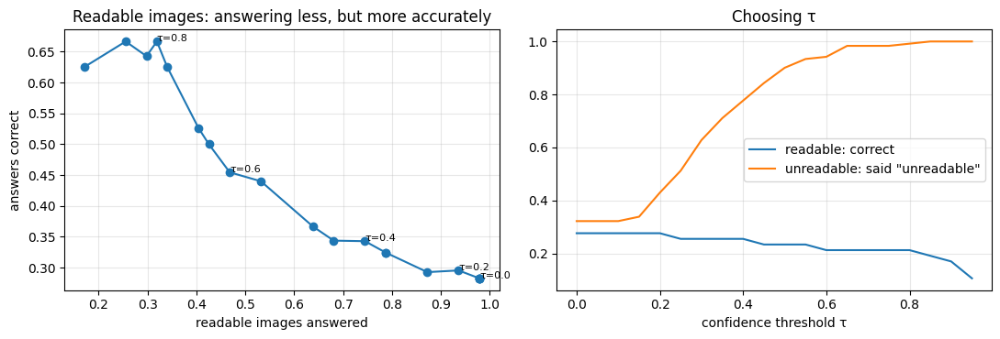

In [ ]:
fm = [frame_metrics(rows_by[MAIN]['lab'], t) for t in TAUS]
for m in fm[::2]:
    print(fmt(m))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot([m['coverage'] for m in fm], [m['precision'] for m in fm], 'o-')
for m in fm[::4]:
    ax[0].annotate(f"τ={m['tau']}", (m['coverage'], m['precision']), fontsize=8)
ax[0].set_xlabel('readable images answered'); ax[0].set_ylabel('answers correct'); ax[0].grid(alpha=.3)
ax[0].set_title('Readable images: answering less, but more accurately')
ax[1].plot(TAUS, [m['accuracy'] for m in fm], label='readable: correct')
ax[1].plot(TAUS, [m['abstain_unreadable'] for m in fm], label='unreadable: said "unreadable"')
ax[1].set_xlabel('confidence threshold τ'); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title('Choosing τ')
plt.tight_layout(); plt.savefig(os.path.join(FIGS, 'tau_tradeoff.png'), dpi=150); plt.show()

### 6.3 Accuracy vs image quality (readable images, τ = 0)

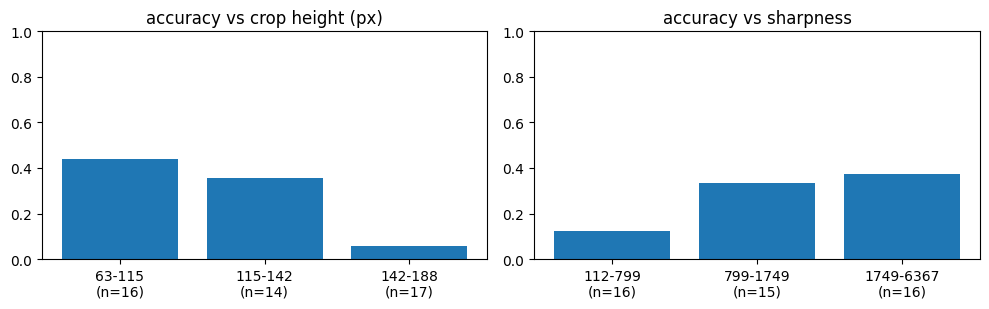

In [ ]:
rd = [r for r in rows_by[MAIN]['lab'] if r['legible']]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, key, name in ((ax[0], 'h', 'crop height (px)'), (ax[1], 'sharp', 'sharpness')):
    vals = np.array([r[key] for r in rd]); okk = np.array([r['pred'] == r['gt'] for r in rd])
    edges = np.percentile(vals, [0, 33, 67, 100])
    bins = np.digitize(vals, edges[1:-1])                         # 0, 1, 2 = lower / middle / upper third
    a.bar([f'{edges[i]:.0f}-{edges[i+1]:.0f}\n(n={(bins == i).sum()})' for i in range(3)],
          [okk[bins == i].mean() if (bins == i).any() else 0 for i in range(3)])
    a.set_ylim(0, 1); a.set_title(f'accuracy vs {name}')
plt.tight_layout(); plt.savefig(os.path.join(FIGS, 'accuracy_vs_quality.png'), dpi=150); plt.show()

## A1: Ablation study
Turn off **one** component at a time and measure the drop. Scored on the readable images (exact number) and on
val players (overall, at the main τ). Every row changes only one thing compared with the full pipeline.

Full pipeline                          readable exact  13/47 ( 28%)   val overall 0.40
Generic HSV grass mask                 readable exact  11/47 ( 23%)   val overall 0.39
Search only the shirt-colour region    readable exact   8/47 ( 17%)   val overall 0.38
No local-contrast masks                readable exact  14/47 ( 30%)   val overall 0.42
No stricter thresholds                 readable exact  10/47 ( 21%)   val overall 0.36
No border clearing                     readable exact  14/47 ( 30%)   val overall 0.38
Only the best candidate (top-1)        readable exact   9/47 ( 19%)   val overall 0.38
Product instead of geometric mean      readable exact  12/47 ( 26%)   val overall 0.38
No lone-"1" penalty                    readable exact  13/47 ( 28%)   val overall 0.39
Synthetic training digits only         readable exact   7/47 ( 15%)   val overall 0.34


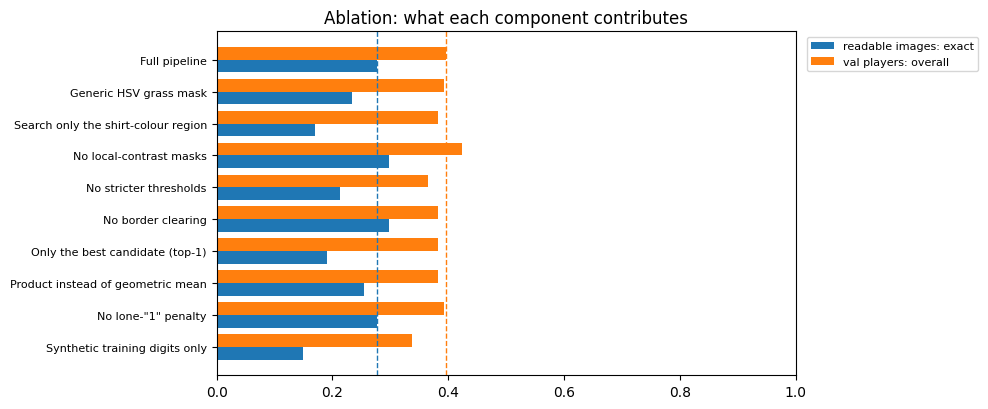

In [ ]:
ABLATIONS = [
    ('Full pipeline', {}),
    ('Generic HSV grass mask', dict(grass='hsv')),
    ('Search only the shirt-colour region', dict(search='shirt')),
    ('No local-contrast masks', dict(local_mask=False)),
    ('No stricter thresholds', dict(strict=False)),
    ('No border clearing', dict(clear_border=False)),
    ('Only the best candidate (top-1)', dict(top_k=1)),
    ('Product instead of geometric mean', dict(geo_mean=False)),
    ('No lone-"1" penalty', dict(one_penalty=1.0)),
    ('Synthetic training digits only', 'SYN_ONLY'),
]
ABLATION_ON_VAL = True        # ~1 min per row on val (cached after the first run)

from sklearn.base import clone
rec_main = recognizers[MAIN]
abl = []
for name, change in ABLATIONS:
    rec, changes = rec_main, ({} if change == 'SYN_ONLY' else change)
    if change == 'SYN_ONLY':
        rec = cached(f'rec_{MAIN.replace("+", "_")}_synonly', lambda: (
            FeatureRecognizer(rec_main.features, clone(rec_main.model.steps[-1][1]))
            if isinstance(rec_main, FeatureRecognizer) else CNNRecognizer()).fit(X_syn[tr_s], y_syn[tr_s]))
    with use_cfg(**changes):
        e, c, n = readable_score(rec)
        key = re.sub(r'\W+', '_', name.lower())
        val = (player_metrics(cached(f'abl_{MAIN.replace("+", "_")}_{key}', lambda: read_all(val_items, rec, name)), TAU)['overall']
               if ABLATION_ON_VAL else float('nan'))
    abl.append((name, e / max(1, n), val))
    print(f'{name:38s} readable exact {e:3d}/{n} ({e/max(1,n):4.0%})   val overall {val:.2f}')

fig, ax = plt.subplots(figsize=(10, 4.2))
names_ = [a[0] for a in abl][::-1]
ax.barh(np.arange(len(abl)) - .2, [a[1] for a in abl][::-1], .4, label='readable images: exact')
ax.barh(np.arange(len(abl)) + .2, [a[2] for a in abl][::-1], .4, label='val players: overall')
ax.set_yticks(range(len(abl))); ax.set_yticklabels(names_, fontsize=8); ax.set_xlim(0, 1)
ax.axvline(abl[0][1], ls='--', lw=1, c='C0'); ax.axvline(abl[0][2], ls='--', lw=1, c='C1')
ax.set_title('Ablation: what each component contributes'); ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig(os.path.join(FIGS, 'ablation.png'), dpi=150); plt.show()

## A2: Digit confusion matrix
Which digits get mistaken for which, on **held-out real digits**. Read each row as "true digit → predicted".
Confusions can be explained by shape (e.g. 3 vs 8 differ only by closing the left side).

Caveat: real digits were harvested with a classifier's help, so they are a bit easier than average.

shape+kNN most common confusions: 3→1 (4x), 6→5 (3x), 0→9 (3x), 9→7 (2x), 9→6 (2x)
CNN most common confusions: 9→1 (3x), 6→8 (2x), 6→5 (2x), 6→1 (2x), 4→6 (2x)


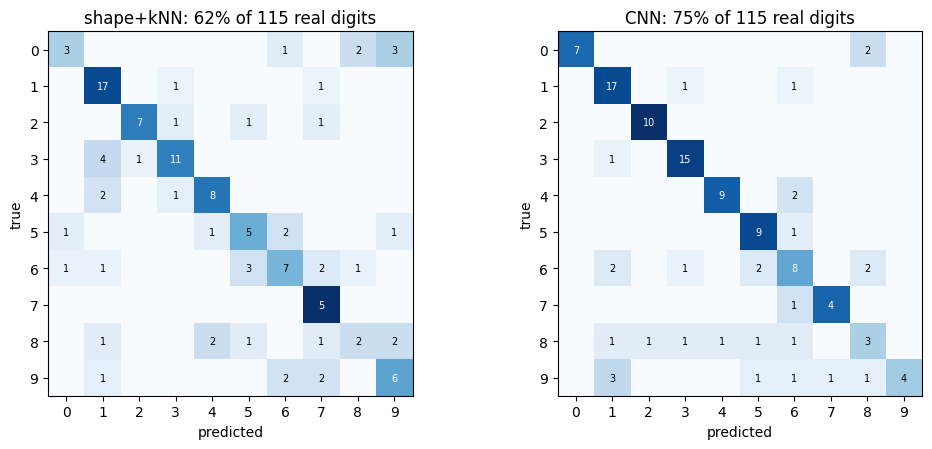

In [ ]:
from sklearn.metrics import confusion_matrix

show = [n for n in ('shape+kNN', MAIN) if n in recognizers]
fig, axes = plt.subplots(1, len(show), figsize=(5.2 * len(show), 4.6))
for ax, name in zip(np.atleast_1d(axes), show):
    pred = recognizers[name].predict_proba(list(X_te_real)).argmax(1)
    cm = confusion_matrix(y_te_real, pred, labels=range(10))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7, color='white' if cmn[i, j] > .5 else 'black')
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title(f'{name}: {(pred == y_te_real).mean():.0%} of {len(pred)} real digits')
    pairs = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)[:5]
    print(f'{name} most common confusions:', ', '.join(f'{i}→{j} ({n}x)' for n, i, j in pairs if n))
plt.tight_layout(); plt.savefig(os.path.join(FIGS, 'confusion.png'), dpi=150); plt.show()

## A3: Pipeline walkthrough figure
One player image through every stage. Good for the presentation and for explaining any part of the pipeline.

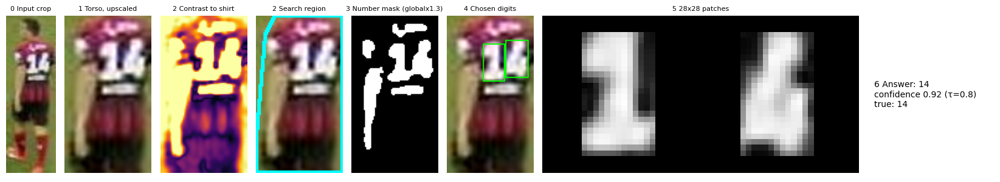

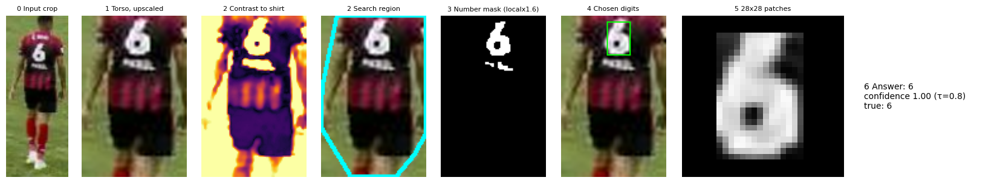

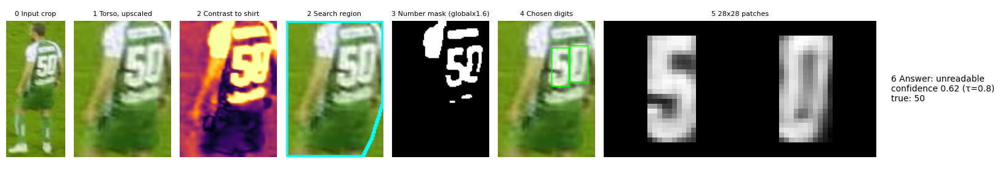

In [ ]:
def walkthrough(it, rec=None, save=None):
    rec = rec or recognizers[MAIN]
    img = cv2.imread(it['path']); t = upscale(torso_crop(img))
    sa = shirt_analysis(t); masks = number_masks(sa); cands = segment_digits(sa, masks)
    num, conf, cand, _ = read_number(t, rec)
    to3 = lambda m: cv2.cvtColor((m * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    region = t.copy()
    cnts, _ = cv2.findContours(sa['region'].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(region, cnts, -1, (255, 255, 0), 2)
    mask = masks[cand['source']] if cand else np.zeros(t.shape[:2], bool)
    patches = candidate_patches(sa, cand) if cand else [np.zeros((28, 28), np.uint8)]
    panels = [(cv2.resize(img, (int(img.shape[1] * 128 / img.shape[0]), 128)), '0 Input crop'),
              (t, '1 Torso, upscaled'),
              (cv2.applyColorMap(np.clip(sa['dE'] * 2.5, 0, 255).astype(np.uint8), cv2.COLORMAP_INFERNO), '2 Contrast to shirt'),
              (region, '2 Search region'),
              (to3(mask), f"3 Number mask ({cand['source'] if cand else '-'})"),
              (draw_boxes(t, cand['boxes'] if cand else [], (0, 255, 0)), '4 Chosen digits'),
              (cv2.cvtColor(np.hstack(patches), cv2.COLOR_GRAY2BGR), '5 28x28 patches')]
    fig, ax = plt.subplots(1, len(panels) + 1, figsize=(2.1 * (len(panels) + 1), 3),
                           gridspec_kw=dict(width_ratios=[p.shape[1] / p.shape[0] for p, _ in panels] + [0.8]))
    for a, (p, title) in zip(ax, panels):
        a.imshow(p[..., ::-1]); a.set_title(title, fontsize=8); a.axis('off')
    ax[-1].axis('off')
    ax[-1].text(0.05, 0.5, f"6 Answer: {num if num is not None and conf >= TAU else 'unreadable'}\n"
                f"confidence {conf:.2f} (τ={TAU})\ntrue: {it['gt']}", fontsize=10, va='center')
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(FIGS, save), dpi=150)
    plt.show()

right = [it for it in readable if read_number(get_torso(it['path']), recognizers[MAIN])[0] == it['gt']]
wrong = [it for it in readable if it not in right]
for i, it in enumerate(right[:2]):
    walkthrough(it, save=f'walkthrough_correct_{i}.png')
if wrong:
    walkthrough(wrong[0], save='walkthrough_failure.png')

## A4: Deblurring before reading
Blur was the clearest accuracy factor. Two classic ways to sharpen before Steps 2–5:
* **Unsharp masking**: add back the difference between the image and a blurred copy (boosts edges).
* **Wiener deconvolution**: undo a known blur in the frequency domain. We assume horizontal **motion blur**
  (players run sideways) of length L px; K stops noise from exploding where the blur removed information.

The classifiers were trained on non-deblurred digits, so this tests deblurring as a plug-in step.

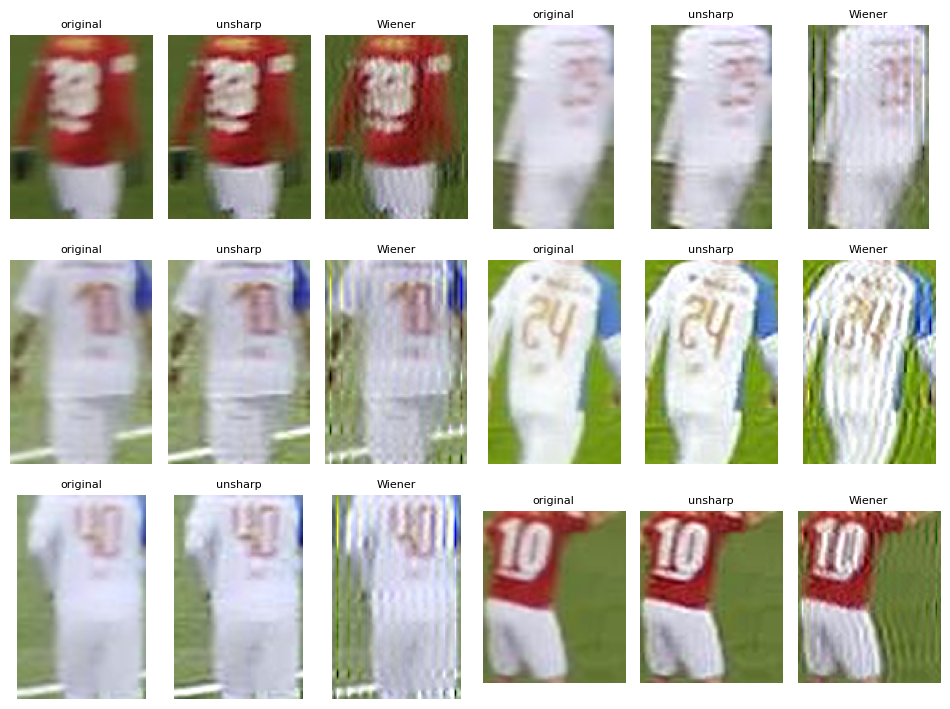

In [ ]:
def unsharp(img, sigma=2.0, amount=1.0):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)

def wiener(img, L=7, K=0.01):
    """Wiener deconvolution with a horizontal motion-blur kernel of length L (per colour channel)."""
    psf = np.zeros(img.shape[:2], np.float32)
    psf[0, :L] = 1 / L
    psf = np.roll(psf, -(L // 2), axis=1)                        # centre the kernel at the origin
    Hf = np.fft.fft2(psf)
    G = np.conj(Hf) / (np.abs(Hf) ** 2 + K)                      # Wiener filter
    out = np.stack([np.real(np.fft.ifft2(np.fft.fft2(img[..., c].astype(np.float32)) * G)) for c in range(3)], 2)
    return np.clip(out, 0, 255).astype(np.uint8)

def deblur(img, how):
    return unsharp(img) if how == 'unsharp' else wiener(img) if how == 'wiener' else img

blurry = sorted(readable, key=lambda it: it['sharp'])[:6]
tiles = []
for it in blurry:
    t = get_torso(it['path'])
    tiles += [t, unsharp(t), wiener(t)]
show_grid(tiles, ['original', 'unsharp', 'Wiener'] * len(blurry), cols=6, size=1.6)

In [ ]:
sh = np.array([it['sharp'] for it in readable])
blur_third = [it for it in readable if it['sharp'] <= np.percentile(sh, 33)]
print(f"{'preprocessing':12s} {'all readable':>14s} {'blurriest third':>16s} {'val overall':>12s}")
for how in (None, 'unsharp', 'wiener'):
    with use_cfg(deblur=how):
        e, _, n = readable_score(recognizers[MAIN])
        eb, _, nb = readable_score(recognizers[MAIN], blur_third)
        val = player_metrics(cached(f'deblur_{MAIN.replace("+", "_")}_{how}', lambda: read_all(val_items, recognizers[MAIN], str(how))), TAU)['overall']
    print(f"{str(how):12s} {e:5d}/{n} ({e/max(1,n):4.0%}) {eb:7d}/{nb} ({eb/max(1,nb):4.0%}) {val:12.2f}")

preprocessing   all readable  blurriest third  val overall
None            13/47 ( 28%)       2/16 ( 12%)         0.40
unsharp         13/47 ( 28%)       2/16 ( 12%)         0.41
wiener          11/47 ( 23%)       2/16 ( 12%)         0.39


# Part B: Improvements
Three add-ons, tested with the main classifier. Each is a switch, so the results above are unchanged.

| | Problem | Idea |
|---|---|---|
| B1 | Pale numbers on white kits are missed | **Chroma contrast**: compare only the colour channels (LAB a, b), ignore brightness |
| B2 | Accuracy drops for the largest players | **Multi-crop**: try 3 torso windows, keep the most confident reading |
| B3 | Frames without a visible number still vote | **Visibility classifier**: only frames judged "number visible" vote |

## B1 + B2: Reading improvements

**B1 Chroma contrast.** Shading on a white shirt changes mostly the **brightness** (L), while an orange number
differs in **colour** (a, b). A contrast map on a and b only makes pale coloured numbers stand out.

**B2 Multi-crop.** The fixed torso window (drop top 1/6, bottom 1/3) may cut the number on close-up players.
We also try a window reaching lower and one starting higher, and keep the reading with the highest confidence.

In [ ]:
CROPS3 = ((1/6, 1/3), (0.10, 0.20), (0.05, 0.40))     # default | taller (reaches lower) | higher

def white_kit(it):
    """True if the shirt colour found in Step 2 is near-white (bright, almost no colour)."""
    sa = shirt_analysis(get_torso(it['path']))
    return sa is not None and sa['shirt'][0] > 170 and np.hypot(sa['shirt'][1] - 128, sa['shirt'][2] - 128) < 12

white = [it for it in readable if white_kit(it)]
hs = np.array([it['h'] for it in readable])
large = [it for it in readable if it['h'] >= np.percentile(hs, 67)]
print(f'readable: {len(readable)} | white kits: {len(white)} | largest third: {len(large)}')

def pct(e, n):
    return f'{e:2d}/{n:<2d} ({e/max(1,n):4.0%})'

VARIANTS = [('Current pipeline', {}),
            ('B1 chroma contrast', dict(chroma_mask=True)),
            ('B2 multi-crop', dict(crops=CROPS3)),
            ('B1 + B2', dict(chroma_mask=True, crops=CROPS3))]
rec_main = recognizers[MAIN]
variant_scores = {}
print(f"\n{'variant':20s} {'all readable':>15s} {'white kits':>15s} {'largest third':>15s} {'val overall':>12s}")
for name, change in VARIANTS:
    with use_cfg(**change):
        e, _, n = readable_score(rec_main)
        ew, _, nw = readable_score(rec_main, white)
        el, _, nl = readable_score(rec_main, large)
        key = re.sub(r'\W+', '_', name.lower())
        val = player_metrics(cached(f'imp_{MAIN.replace("+", "_")}_{key}_val',
                                    lambda: read_all(val_items, rec_main, name)), TAU)['overall']
    variant_scores[name] = val
    print(f'{name:20s} {pct(e, n):>15s} {pct(ew, nw):>15s} {pct(el, nl):>15s} {val:12.2f}')

BEST_VARIANT = max(variant_scores, key=variant_scores.get)          # chosen on VAL, not test
BEST_CFG = dict(VARIANTS)[BEST_VARIANT]
print(f'\nbest on val: {BEST_VARIANT}')

readable: 47 | white kits: 15 | largest third: 17

variant                 all readable      white kits   largest third  val overall
Current pipeline        13/47 ( 28%)     0/15 (  0%)     1/17 (  6%)         0.40
B1 chroma contrast      14/47 ( 30%)     1/15 (  7%)     1/17 (  6%)         0.39
B2 multi-crop           15/47 ( 32%)     3/15 ( 20%)     1/17 (  6%)         0.37
B1 + B2                 15/47 ( 32%)     3/15 ( 20%)     1/17 (  6%)         0.36

best on val: Current pipeline


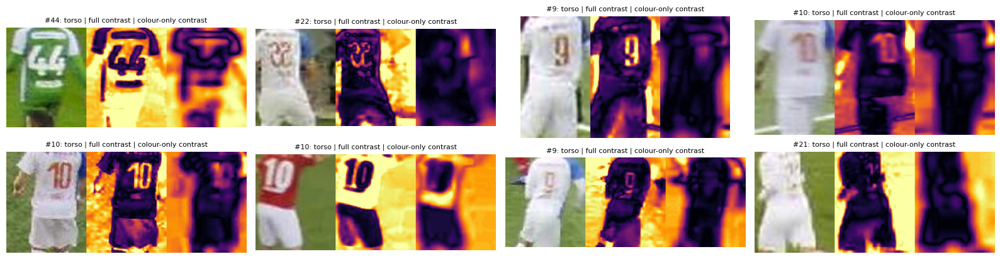

In [ ]:
# Before / after on white kits: does the chroma map show the number?
if white:
    to3 = lambda m: cv2.cvtColor((m * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
    panels = []
    for it in white[:8]:
        t = get_torso(it['path']); sa = shirt_analysis(t)
        chroma = np.linalg.norm(sa['lab'][..., 1:] - sa['shirt'][1:], axis=2)
        panels.append(np.hstack([t, cv2.applyColorMap(np.clip(sa['dE'] * 2.5, 0, 255).astype(np.uint8), cv2.COLORMAP_INFERNO),
                                 cv2.applyColorMap(np.clip(chroma * 5, 0, 255).astype(np.uint8), cv2.COLORMAP_INFERNO)]))
    show_panels(panels, [f"#{it['gt']}: torso | full contrast | colour-only contrast" for it in white[:8]])

Test score of the best variant (one run, cached):

In [ ]:
with use_cfg(**BEST_CFG):
    key = re.sub(r'\W+', '_', BEST_VARIANT.lower())
    rows_best_val = cached(f'imp_{MAIN.replace("+", "_")}_{key}_val', lambda: read_all(val_items, rec_main))
    rows_best_test = cached(f'imp_{MAIN.replace("+", "_")}_{key}_test', lambda: read_all(test_items, rec_main, 'test'))
TAU_B = max(TAUS, key=lambda t: player_metrics(rows_best_val, t)['overall'])
print(f'{BEST_VARIANT} (τ={TAU_B}) TEST:', fmt(player_metrics(rows_best_test, TAU_B)))
print(f'before            (τ={TAU}) TEST:', fmt(results[MAIN]['test']))

  test 2000/7242 frames, 51s
  test 4000/7242 frames, 103s
  test 6000/7242 frames, 151s
Current pipeline (τ=0.8) TEST: tau=0.80 | players=1211 | overall=0.40 | visible_acc=0.19 | visible_coverage=0.39 | visible_precision=0.47 | abstain_on_no_number=0.93
before            (τ=0.8) TEST: tau=0.80 | players=1211 | overall=0.40 | visible_acc=0.19 | visible_coverage=0.39 | visible_precision=0.47 | abstain_on_no_number=0.93


## B3: Visibility (legibility) classifier
A small classifier answers one question per frame: **is a number visible here?** Only "yes" frames vote.
Koshkina & Elder (2024) use the same idea with a deep network; ours uses simple features the pipeline already
computes, and a **logistic regression** or **random forest** trained from scratch.

**Training labels (dev frames only):**
* **visible** = hand-labelled readable dev frames (both label files),
* **not visible** = hand-labelled unreadable dev frames + every frame of a **-1** player (free labels).

More "visible" examples make it better: set `RUN_LABELLING = True` and `LABEL_SPLIT = 'dev'` in the setup cell,
label ~300 more frames, then rerun from Step 1.3. Those labels are saved to a separate file
(`legible_labels_b3.json`) and used **only here**, so the readable test set above stays unchanged.

In [ ]:
FEATURES = ['confidence', 'n_candidates', 'best_score', 'n_digits', 'digit_height', 'digit_contrast',
            'log_sharpness', 'crop_height']

def frame_row(it, rec):
    """Read one frame and keep the features B3 learns from."""
    img = cv2.imread(it['path'])
    num, conf, cand, preds = None, 0.0, None, []
    if img is not None and img.shape[0] >= MIN_H:
        num, conf, cand, preds, _ = read_image(img, rec)
    boxes = cand['boxes'] if cand else []
    f = [conf, len(preds), cand['score'] if cand else -1, len(boxes),
         np.mean([b['h'] for b in boxes]) / TORSO_H if boxes else 0,
         np.mean([b['contrast'] for b in boxes]) if boxes else 0,
         np.log10(it['sharp'] + 1), it['h']]
    return dict(path=it['path'], tid=it['tid'], gt=it['gt'], pred=num, conf=conf, feats=f,
                h=it['h'], sharp=it['sharp'], legible=legible.get(it['path']))

def visible_label(r):
    """Training label for B3: hand label from either file, else 'not visible' for -1 players, else unknown."""
    lab = legible_b3.get(r['path'], legible.get(r['path']))
    return int(lab) if lab is not None else (0 if r['gt'] < 0 else None)

def frame_rows(items_, rec, label=''):
    t0, out = time.time(), []
    for i, it in enumerate(items_):
        out.append(frame_row(it, rec))
        if (i + 1) % 2000 == 0:
            print(f'  {label} {i+1}/{len(items_)} frames, {time.time()-t0:.0f}s')
    return out

dev_items = [it for it in items if it['split'] == 'dev']
key = re.sub(r'\W+', '_', BEST_VARIANT.lower())
with use_cfg(**BEST_CFG):
    rows_dev = cached(f'b3_{MAIN.replace("+", "_")}_{key}_dev', lambda: frame_rows(dev_items, rec_main, 'dev'))
    rows_val3 = cached(f'b3_{MAIN.replace("+", "_")}_{key}_val', lambda: frame_rows(val_items, rec_main, 'val'))
    rows_test3 = cached(f'b3_{MAIN.replace("+", "_")}_{key}_test', lambda: frame_rows(test_items, rec_main, 'test'))

# training set: dev frames with a known answer to "is a number visible?"
X_leg, y_leg = [], []
for r in rows_dev:
    lab = visible_label(r)
    if lab is not None:
        X_leg.append(r['feats']); y_leg.append(lab)
X_leg, y_leg = np.array(X_leg), np.array(y_leg)
print(f'visibility training set: {len(y_leg)} frames, {y_leg.sum()} visible, {(y_leg == 0).sum()} not visible')
if y_leg.sum() < 60:
    print('  few "visible" examples: label more dev frames for a better classifier (see above)')

visibility training set: 3081 frames, 306 visible, 2775 not visible


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

models = {
    'logistic regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for name, m in models.items():
    auc = cross_val_score(m, X_leg, y_leg, cv=cv, scoring='roc_auc')
    print(f'{name:20s} 5-fold AUC {auc.mean():.2f} ± {auc.std():.2f}   (0.5 = guessing, 1.0 = perfect)')
    m.fit(X_leg, y_leg)

# which features matter (explainable!)
coef = models['logistic regression'][-1].coef_[0]
imp = models['random forest'].feature_importances_
print(f"\n{'feature':16s} {'LR weight':>10s} {'RF importance':>14s}")
for f, c, i in sorted(zip(FEATURES, coef, imp), key=lambda x: -x[2]):
    print(f'{f:16s} {c:10.2f} {i:14.2f}')

logistic regression  5-fold AUC 0.89 ± 0.02   (0.5 = guessing, 1.0 = perfect)
random forest        5-fold AUC 0.88 ± 0.02   (0.5 = guessing, 1.0 = perfect)

feature           LR weight  RF importance
crop_height            1.40           0.28
confidence             0.82           0.21
digit_height          -0.67           0.12
best_score             1.23           0.10
digit_contrast        -0.74           0.10
log_sharpness          0.69           0.09
n_candidates           0.33           0.09
n_digits              -0.19           0.01


**Gated vote:** a frame votes only if P(visible) ≥ λ **and** confidence ≥ τ. λ and τ are chosen on val players;
test is scored once.

In [ ]:
def gated_metrics(rows, model, lam, tau):
    p = model.predict_proba(np.array([r['feats'] for r in rows]))[:, 1]
    gated = [dict(r, conf=r['conf'] if pv >= lam else 0.0) for r, pv in zip(rows, p)]   # gated frames don't vote
    return player_metrics(gated, tau)

best = None
for mname, m in models.items():
    for lam in (0.0, 0.3, 0.5, 0.7, 0.85):
        for tau in TAUS:
            v = gated_metrics(rows_val3, m, lam, tau)['overall']
            if best is None or v > best[0]:
                best = (v, mname, lam, tau)
_, LEG_MODEL, LAM, TAU_G = best
print(f'chosen on val: {LEG_MODEL}, λ = {LAM}, τ = {TAU_G}')

res_gate = gated_metrics(rows_test3, models[LEG_MODEL], LAM, TAU_G)
res_nogate = player_metrics(rows_test3, TAU_B)
print(f"\n{'TEST players':26s} {'no gate':>10s} {'with gate':>10s}")
for k, label in cols:
    print(f'{label:26s} {res_nogate[k]:10.2f} {res_gate[k]:10.2f}')

improvements = dict(variant=BEST_VARIANT, tau=float(TAU_B), test_no_gate=res_nogate,
                    gate=dict(model=LEG_MODEL, lam=LAM, tau=float(TAU_G), test=res_gate))
json.dump(improvements, open(os.path.join(WORK, 'partB_results.json'), 'w'), indent=2)

chosen on val: random forest, λ = 0.5, τ = 0.2

TEST players                  no gate  with gate
Overall                          0.40       0.42
Visible: read                    0.19       0.24
Visible: answered                0.39       0.58
Correct when answering           0.47       0.41
No number: "unreadable"          0.93       0.86


In [ ]:
wk = {it['path'] for it in white}
print(sum(it['path'] in wk for it in large), 'of', len(large), 'largest-third readable images are white kits')

8 of 17 largest-third readable images are white kits


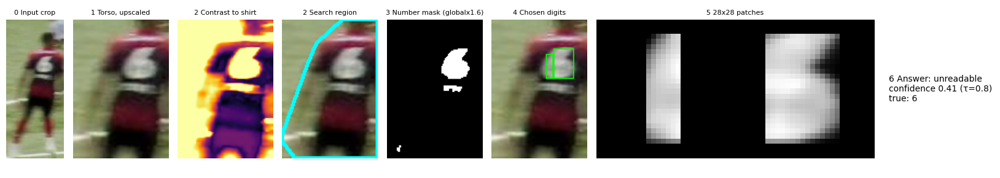

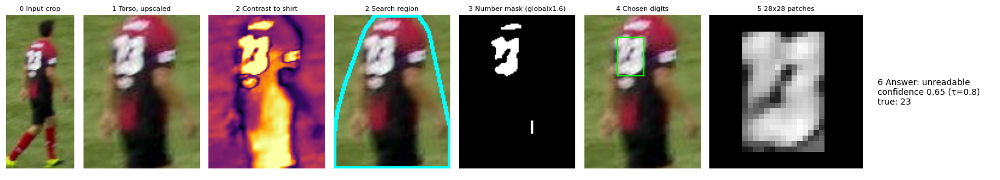

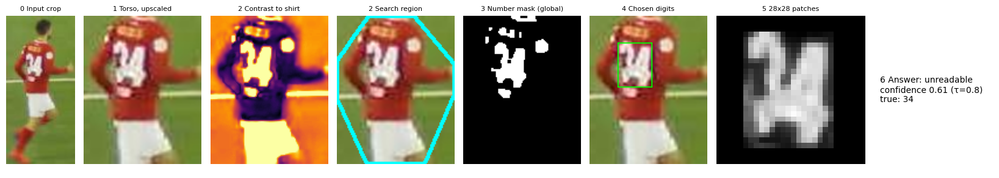

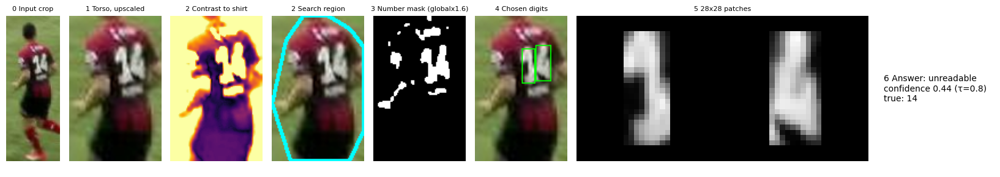

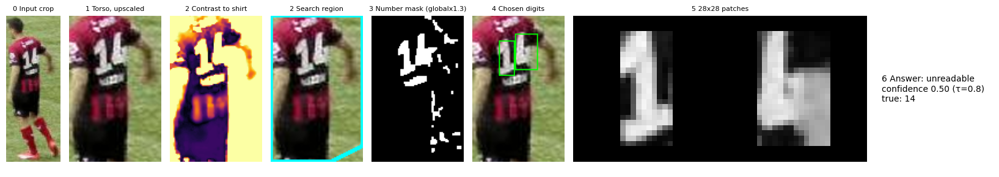

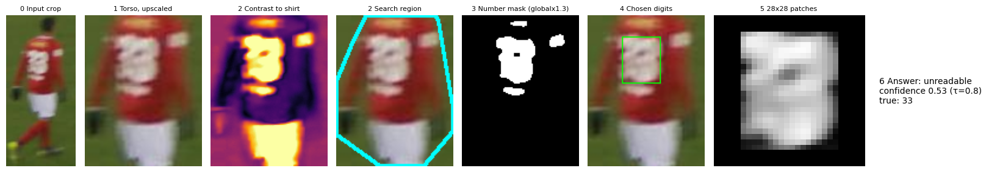

In [ ]:
nonwhite_large = [it for it in large if it['path'] not in wk]
for it in nonwhite_large[:6]:
    walkthrough(it)

## B4: Separating touching digits with erosion
On close-up players the digits are big, thick and motion-blurred, so the two digits **touch** and Step 4 sees one blob
(e.g. "23", "33", "34" read as a single digit). **Erosion** shrinks every white blob by one pixel per step; the thin
bridge between two digits disappears first, so they become two separate blobs.

We **add** eroded copies of every Step 3 mask (1, 2 or 3 erosion steps with a 3x3 kernel) instead of replacing them,
so the reader can still pick the un-eroded version when that reads better. Scored like B1/B2; the best setting is
chosen on val.

In [ ]:
CFG.setdefault('erode', 0)          # B4: 0 = off, n = also add masks eroded n times
_number_masks_base = number_masks if '_number_masks_base' not in globals() else _number_masks_base

def number_masks(sa):
    """Step 3 masks, plus (B4) eroded copies that separate touching digits."""
    out = _number_masks_base(sa)
    if CFG['erode']:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        for name, m in list(out.items()):
            er = cv2.erode(m.astype(np.uint8), k, iterations=CFG['erode']) > 0   # thin bridges vanish first
            out[f'{name}_er{CFG["erode"]}'] = er
    return out

In [ ]:
wk = {it['path'] for it in white}
nonwhite_large = [it for it in large if it['path'] not in wk]

B4_VARIANTS = [('Current pipeline', {}), ('B4 erode x1', dict(erode=1)),
               ('B4 erode x2', dict(erode=2)), ('B4 erode x3', dict(erode=3))]
b4_val = {}
print(f"{'variant':18s} {'all readable':>15s} {'largest third':>15s} {'large, not white':>17s} {'val overall':>12s}")
for name, change in B4_VARIANTS:
    with use_cfg(**change):
        e, _, n = readable_score(rec_main)
        el, _, nl = readable_score(rec_main, large)
        en, _, nn = readable_score(rec_main, nonwhite_large)
        key = re.sub(r'\W+', '_', name.lower())
        rows_v = cached(f'b4_{MAIN.replace("+", "_")}_{key}_val', lambda: read_all(val_items, rec_main, name))
    b4_val[name] = player_metrics(rows_v, TAU)['overall']
    print(f'{name:18s} {pct(e, n):>15s} {pct(el, nl):>15s} {pct(en, nn):>17s} {b4_val[name]:12.2f}')

B4_BEST = max(b4_val, key=b4_val.get)                     # chosen on VAL
print(f'\nbest on val: {B4_BEST}')
if B4_BEST != 'Current pipeline':
    with use_cfg(**dict(B4_VARIANTS)[B4_BEST]):
        key = re.sub(r'\W+', '_', B4_BEST.lower())
        rv = cached(f'b4_{MAIN.replace("+", "_")}_{key}_val', lambda: read_all(val_items, rec_main))
        rt = cached(f'b4_{MAIN.replace("+", "_")}_{key}_test', lambda: read_all(test_items, rec_main, 'test'))
    tau_b4 = max(TAUS, key=lambda t: player_metrics(rv, t)['overall'])
    print(f'{B4_BEST} (τ={tau_b4}) TEST:', fmt(player_metrics(rt, tau_b4)))
    print(f'before          (τ={TAU}) TEST:', fmt(results[MAIN]['test']))

variant               all readable   largest third  large, not white  val overall
Current pipeline      13/47 ( 28%)     1/17 (  6%)       1/9  ( 11%)         0.40
B4 erode x1           11/47 ( 23%)     0/17 (  0%)       0/9  (  0%)         0.40
B4 erode x2           10/47 ( 21%)     0/17 (  0%)       0/9  (  0%)         0.40
B4 erode x3           12/47 ( 26%)     1/17 (  6%)       1/9  ( 11%)         0.39

best on val: B4 erode x1
  test 2000/7242 frames, 61s
  test 4000/7242 frames, 119s
  test 6000/7242 frames, 173s
B4 erode x1 (τ=0.7) TEST: tau=0.70 | players=1211 | overall=0.41 | visible_acc=0.22 | visible_coverage=0.48 | visible_precision=0.45 | abstain_on_no_number=0.86
before          (τ=0.8) TEST: tau=0.80 | players=1211 | overall=0.40 | visible_acc=0.19 | visible_coverage=0.39 | visible_precision=0.47 | abstain_on_no_number=0.93


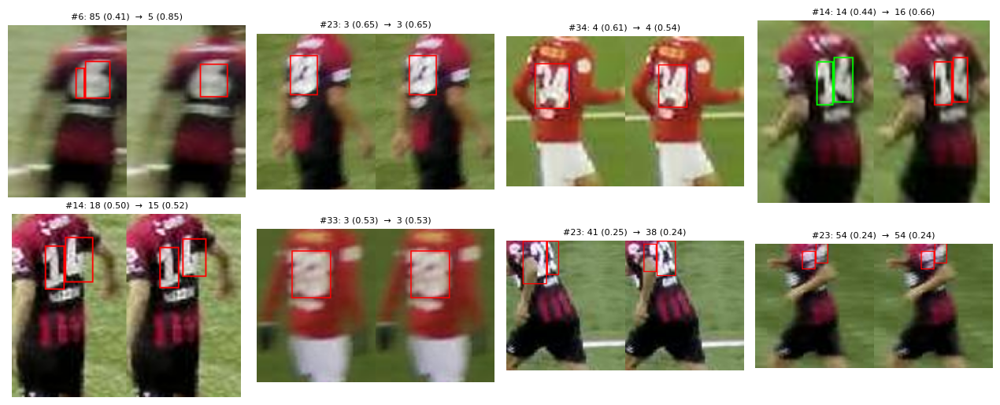

In [ ]:
# Chosen digit boxes without and with erosion (green = right number, red = wrong)
level = dict(B4_VARIANTS)[B4_BEST].get('erode', 2) or 2
panels, titles = [], []
for it in nonwhite_large[:8]:
    img = cv2.imread(it['path']); row = []
    for e in (0, level):
        with use_cfg(erode=e):
            num, conf, cand, _, t = read_image(img, rec_main)
        col = (0, 255, 0) if num == it['gt'] else (0, 0, 255)
        row.append(draw_boxes(t, cand['boxes'] if cand else [], col))
        titles_part = f"{num} ({conf:.2f})"
        row_title = titles_part if e == 0 else row_title + f"  →  {titles_part}"
    panels.append(np.hstack(row)); titles.append(f"#{it['gt']}: {row_title}")
fig = plt.figure(figsize=(4 * 3.2, math.ceil(len(panels) / 4) * 2.6))
for i, p in enumerate(panels):
    plt.subplot(math.ceil(len(panels) / 4), 4, i + 1); plt.imshow(p[..., ::-1]); plt.title(titles[i], fontsize=8); plt.axis('off')
plt.tight_layout(); plt.savefig(os.path.join(FIGS, 'b4_erosion.png'), dpi=150); plt.show()

## Hand-off to Muzammil's part
`read_from_frame` takes a full match frame and one player box `(x0, y0, x1, y1)` in pixels from his detector.
Convert `(x, y, w, h)` boxes first: `x1 = x + w`, `y1 = y + h`. `read_player` votes over several crops of the
same player. Both use the best reading variant from Part B (chosen on val).

In [ ]:
def read_from_frame(frame_bgr, bbox_xyxy, rec=None, tau=None):
    """Jersey number of one detected player, or None = 'unreadable'. Returns (number, confidence)."""
    rec, tau = rec or recognizers[MAIN], TAU_B if tau is None else tau
    x0, y0, x1, y1 = map(int, bbox_xyxy)
    crop = frame_bgr[max(0, y0):y1, max(0, x0):x1]
    if crop.size == 0 or crop.shape[0] < MIN_H:
        return None, 0.0
    with use_cfg(**BEST_CFG):
        num, conf, _, _, _ = read_image(crop, rec)
    return (num if num is not None and conf >= tau else None), conf

def read_player(crops_bgr, rec=None, tau=None):
    """Several crops of the SAME player -> confidence-weighted vote (None if nothing confident)."""
    rec, tau = rec or recognizers[MAIN], TAU_B if tau is None else tau
    votes = Counter()
    for c in crops_bgr:
        if c is None or c.shape[0] < MIN_H:
            continue
        with use_cfg(**BEST_CFG):
            num, conf, _, _, _ = read_image(c, rec)
        if num is not None and conf >= tau:
            votes[num] += conf
    return votes.most_common(1)[0][0] if votes else None

# quick self-test: a test image placed in a fake 'frame'
it = test_items[0]; crop = cv2.imread(it['path'])
frame = np.zeros((crop.shape[0] + 40, crop.shape[1] + 40, 3), np.uint8); frame[20:-20, 20:-20] = crop
print('read_from_frame:', read_from_frame(frame, (20, 20, 20 + crop.shape[1], 20 + crop.shape[0])), '| true:', it['gt'])

read_from_frame: (None, 0.27455002069473267) | true: 4
